# **4. Exploratory Component: The Cost of Hoarding**

**Research question:** How much charging capacity and revenue does the provider lose to hoarding, can a model predict at plug-in which sessions will hoard, and how should the provider use such a prediction?

Code for Section IV of the paper, which refers to the subsections below (4.1 to 4.6).

### Table of Contents <a class="anchor" id='toc'></a>

* [4.1 Preparing the data](#p4_1)
* [4.2 Describing the problem](#p4_2)
* [4.3 Feature engineering](#p4_3)
* [4.4 Predicting hoarding at plug-in](#p4_4)
* [4.5 Business impact of hoarding](#p4_5)
* [4.6 Conclusions](#p4_6)

-----------------------------------------

## 4.1. Preparing the data <a class="anchor" id="p4_1"></a>

Libraries for data handling and plotting.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import time

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, f1_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

Cleaned sessions from the pre-processing notebook (Section 1.5).

In [ ]:
ev = pd.read_pickle("Data/ev_clean.pkl")
print(ev.shape)

# first rows of the main columns
ev[["station", "start", "end", "total_hours", "charging_hours", "idle_hours", "energy_kwh", "fee", "user_id"]].head()

(245736, 27)


,station,start,end,total_hours,charging_hours,idle_hours,energy_kwh,fee,user_id
0,PALO ALTO CA / HAMILTON #1,2011-07-29 20:17:00,2011-07-29 23:20:32,3.058889,1.900833,1.158056,6.249457,0.0,3284
1,PALO ALTO CA / HAMILTON #1,2011-07-30 00:00:00,2011-07-30 00:02:06,0.035000,0.031667,0.003333,0.106588,0.0,4169
2,PALO ALTO CA / HAMILTON #1,2011-07-30 08:16:00,2011-07-30 12:33:32,4.292222,4.291111,0.001111,14.951777,0.0,4169
3,PALO ALTO CA / HAMILTON #1,2011-07-30 14:51:00,2011-07-30 16:54:24,2.056667,2.049444,0.007222,7.159643,0.0,2545
4,PALO ALTO CA / HAMILTON #1,2011-07-30 18:51:00,2011-07-30 20:02:24,1.190000,0.731667,0.458333,1.957765,0.0,3765


A session counts as hoarding when the car stays plugged in for more than one hour after charging has finished. We also keep a two-hour version to check later whether the conclusions depend on this threshold.

In [3]:
HOARD_THRESHOLD = 1  # hours of idle time

ev["hoarding"] = (ev["idle_hours"] > HOARD_THRESHOLD).astype(int) # > 1 hour of idle = hoarding
ev["hoarding_2h"] = (ev["idle_hours"] > 2).astype(int) # 2 hours of idle

print(f"Hoarding sessions (> 1 h idle): {ev['hoarding'].sum():,} ({ev['hoarding'].mean() * 100:.1f}%)")
print(f"Hoarding sessions (> 2 h idle): {ev['hoarding_2h'].sum():,} ({ev['hoarding_2h'].mean() * 100:.1f}%)")

Hoarding sessions (> 1 h idle): 30,409 (12.4%)
Hoarding sessions (> 2 h idle): 14,868 (6.1%)


Checks: idle time should never be negative after cleaning, and the target must have no missing values.

In [4]:
# idle time and target checks
print("Negative idle time:", (ev["idle_hours"] < 0).sum())
print("Missing idle time:", ev["idle_hours"].isna().sum())
print("Missing target:", ev["hoarding"].isna().sum())
ev["idle_hours"].describe().round(2)

Negative idle time: 0
Missing idle time: 0
Missing target: 0


count    245736.00
mean          0.50
std           1.40
min           0.00
25%           0.00
50%           0.01
75%           0.37
max          22.40
Name: idle_hours, dtype: float64

-----------------------------------------

## 4.2. Describing the problem <a class="anchor" id="p4_2"></a>
  
[Back to TOC](#toc)

Share of hoarding sessions by the hour the car is plugged in.

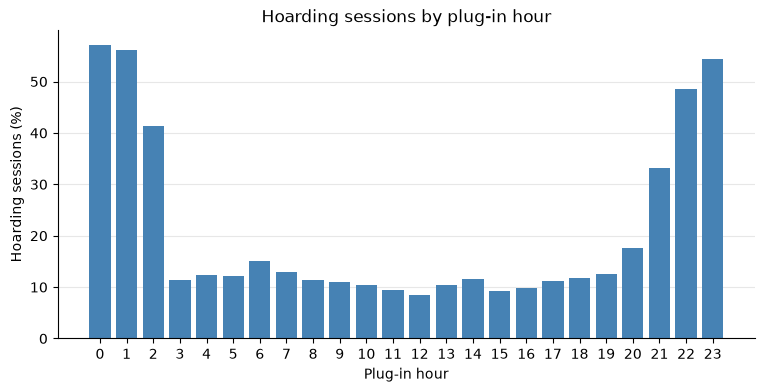

Hoarding, all years: night 51.1%, day 11.4%
Hoarding, 2018-2019: night 26.5%, day 8.2%


In [5]:
# start hour of the session
ev["start_hour"] = ev["start"].dt.hour  

# percentage of hoarding sessions by hour
by_hour = ev.groupby("start_hour")["hoarding"].mean() * 100 

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(by_hour.index, by_hour.values, color="steelblue")
ax.set_title("Hoarding sessions by plug-in hour")
ax.set_xlabel("Plug-in hour")
ax.set_ylabel("Hoarding sessions (%)")
ax.set_xticks(range(0, 24))
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

# hoarding rate of sessions starting 22:00-00:59 and 07:00-21:59, all years and 2018-2019
night_start = ev["start_hour"].isin([22, 23, 0])
day_start = ev["start_hour"].between(7, 21)
recent_years = ev["start"].dt.year.isin([2018, 2019])
print(f"Hoarding, all years: night {ev.loc[night_start, 'hoarding'].mean() * 100:.1f}%, "
      f"day {ev.loc[day_start, 'hoarding'].mean() * 100:.1f}%")
print(f"Hoarding, 2018-2019: night {ev.loc[night_start & recent_years, 'hoarding'].mean() * 100:.1f}%, "
      f"day {ev.loc[day_start & recent_years, 'hoarding'].mean() * 100:.1f}%")

Share of hoarding sessions by station.

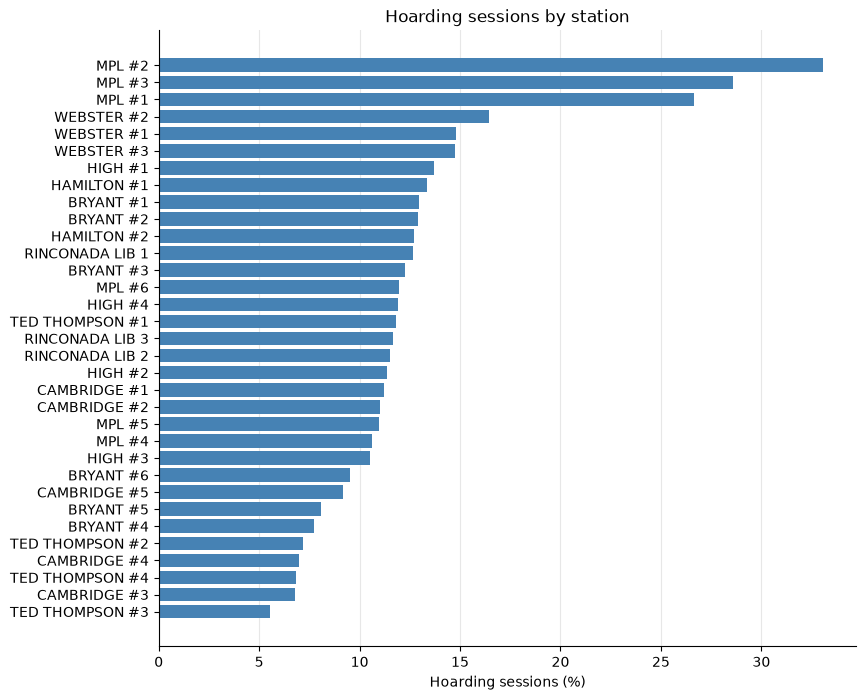

station
WEBSTER #1    14.8
WEBSTER #2    16.4
MPL #1        26.6
MPL #3        28.6
MPL #2        33.1


In [6]:
# percentage of hoarding sessions by station
by_station = (ev.groupby("station", observed=True)["hoarding"].mean() * 100).sort_values() 

# remove the "PALO ALTO CA / " prefix from the names
by_station.index = by_station.index.str.replace("PALO ALTO CA / ", "") 

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(by_station.index, by_station.values, color="steelblue")
ax.set_title("Hoarding sessions by station")
ax.set_xlabel("Hoarding sessions (%)")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.show()

# the stations with the highest hoarding rates (all years)
print(by_station.tail(5).round(1).to_string())

Charger hours blocked by hoarding each year. Idle time counts as daytime when charging finishes between 07:00 and 22:00, the hours when other drivers are most likely to arrive: 95% of sessions in 2018 and 2019 start in this window.

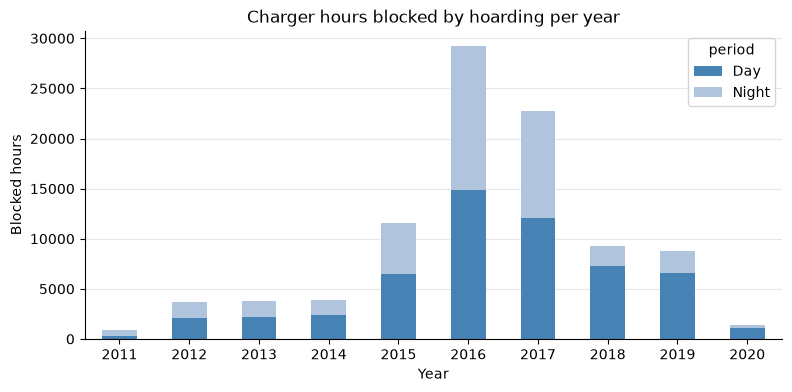

period      Day    Night
start                   
2011      324.0    557.0
2012     2130.0   1574.0
2013     2178.0   1572.0
2014     2379.0   1531.0
2015     6493.0   5094.0
2016    14860.0  14411.0
2017    12053.0  10710.0
2018     7302.0   1963.0
2019     6606.0   2214.0
2020     1079.0    358.0


In [7]:
# hour when the idle period starts
ev["idle_start_hour"] = (ev["start"] + pd.to_timedelta(ev["charging_hours"], unit="h")).dt.hour 

# daytime = 7-21, nighttime = 22-6
ev["period"] = np.where(ev["idle_start_hour"].between(7, 21), "Day", "Night") 

# blocked hours by hoarding per year
blocked = (ev[ev["hoarding"] == 1]
           .groupby([ev["start"].dt.year, "period"])["idle_hours"].sum()
           .unstack())

fig, ax = plt.subplots(figsize=(9, 4))
blocked.plot(kind="bar", stacked=True, ax=ax, color=["steelblue", "lightsteelblue"])
ax.set_title("Charger hours blocked by hoarding per year")
ax.set_xlabel("Year")
ax.set_ylabel("Blocked hours")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print(blocked.round(0))

Daytime charger hours blocked by hoarding per year at each station (top 10). We use only 2018 and 2019, so stations that opened earlier do not score higher just because they have more years of data. In those two years all 33 stations were open by March 2018 and 99.8% of sessions were paid. The 146 unpaid sessions are spread over many stations and months, and half of them lasted under three minutes, so they look like aborted or test plug-ins rather than a free tariff. Six stations opened in March 2018 and have about 22 months of data instead of 24, so their hours per year are slightly underestimated. Correcting for this does not change the top four.

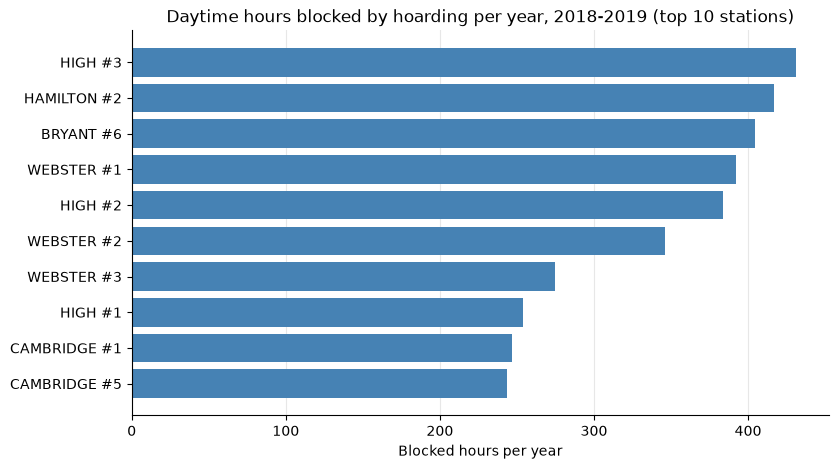

station
HIGH #3         431.0
HAMILTON #2     417.0
BRYANT #6       404.0
WEBSTER #1      392.0
HIGH #2         384.0
WEBSTER #2      346.0
WEBSTER #3      275.0
HIGH #1         254.0
CAMBRIDGE #1    247.0
CAMBRIDGE #5    244.0
Name: idle_hours, dtype: float64
Sessions starting 07:00-22:00 in 2018-2019: 95.0%
Paid sessions: 99.8% | unpaid sessions: 146, of which under 3 minutes: 76
Stations opened in March 2018: 6 (first sessions 2018-03-21 to 2018-03-23), so about 22 months of data in 2018-2019


In [ ]:
# only 2018 and 2019: full years with all stations open (the data end in February 2020)
recent = ev[ev["start"].dt.year.isin([2018, 2019])] 

day_blocked = (recent[(recent["hoarding"] == 1) & (recent["period"] == "Day")]
               .groupby("station", observed=True)["idle_hours"].sum() / 2  
               ).sort_values().tail(10)
day_blocked.index = day_blocked.index.str.replace("PALO ALTO CA / ", "")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(day_blocked.index, day_blocked.values, color="steelblue")
ax.set_title("Daytime hours blocked by hoarding per year, 2018-2019 (top 10 stations)")
ax.set_xlabel("Blocked hours per year")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print(day_blocked.round(0).sort_values(ascending=False))

# share of 2018-2019 sessions that start between 07:00 and 22:00 (the daytime window)
print(f"Sessions starting 07:00-22:00 in 2018-2019: {recent['start_hour'].between(7, 21).mean() * 100:.1f}%")

# facts cited in the text above (2018-2019)
unpaid = recent[recent["fee"] == 0]
print(f"Paid sessions: {(recent['fee'] > 0).mean() * 100:.1f}% | unpaid sessions: {len(unpaid)}, "
      f"of which under 3 minutes: {(unpaid['total_hours'] < 0.05).sum()}")

# stations whose first session falls in March 2018
first_session = recent.groupby("station", observed=True)["start"].min()
opened_march = first_session[first_session >= "2018-03-01"]
print(f"Stations opened in March 2018: {len(opened_march)} (first sessions {opened_march.min().date()} to "
      f"{opened_march.max().date()}), so about 22 months of data in 2018-2019")

What drivers pay on top of the energy price. Most paid sessions cost exactly 0.23 \$/kWh; the check below looks at the sessions that pay more, and at what the extra depends on.

In [9]:
# paid sessions: the fee minus the energy price (0.23 $/kWh) is the extra paid
paid_fee = ev[(ev["fee"] > 0) & (ev["energy_kwh"] > 0)].copy()
paid_fee["extra"] = paid_fee["fee"] - 0.23 * paid_fee["energy_kwh"]
paid_fee["has_extra"] = paid_fee["extra"] > 0.01  # more than one cent above the energy price

print("First paid session:", paid_fee["start"].min())
print(f"Pay only the energy price: {(paid_fee['extra'].abs() <= 0.01).mean() * 100:.1f}%")
print(f"Pay an extra: {paid_fee['has_extra'].mean() * 100:.1f}%")

# what the extra depends on
extra_paid = paid_fee[paid_fee["has_extra"]]
corr_idle = extra_paid["extra"].corr(extra_paid["idle_hours"])
corr_charging = extra_paid["extra"].corr(extra_paid["charging_hours"])
print(f"Correlation of the extra with idle hours: {corr_idle:.2f} (with charging hours: {corr_charging:.2f})")

# straight line through the extra: price per idle hour, and the idle time where it starts
fee_slope, fee_intercept = np.polyfit(extra_paid["idle_hours"], extra_paid["extra"], 1)
free_minutes = -fee_intercept / fee_slope * 60
print(f"About {fee_slope:.1f} $ per idle hour, starting after about {free_minutes:.0f} minutes")

# share of hoarding sessions that pay the extra, by day and night
hoarding_paid = paid_fee[paid_fee["hoarding"] == 1]
extra_by_period = hoarding_paid.groupby("period")["has_extra"].mean() * 100
display(extra_by_period.round(1).rename("hoarding sessions with extra (%)").to_frame())

# where it is charged
station_name = paid_fee["station"].astype(str).str.replace("PALO ALTO CA / ", "")
by_station_fee = (paid_fee.groupby(station_name)["has_extra"].mean() * 100).sort_values(ascending=False)
print("Highest share of sessions with extra (%):")
print(by_station_fee.head(5).round(1).to_string())
print("Never charged:", ", ".join(by_station_fee[by_station_fee == 0].index))


First paid session:

 2017-08-01 05:16:00
Pay only the energy price: 89.0%
Pay an extra: 10.1%
Correlation of the extra with idle hours: 0.97 (with charging hours: 0.22)
About 2.0 $ per idle hour, starting after about 33 minutes


,hoarding sessions with extra (%)
period,
Day,74.1
Night,46.6


Highest share of sessions with extra (%):
station
WEBSTER #2      15.3
BRYANT #6       15.2
CAMBRIDGE #5    14.7
HIGH #2         14.4
WEBSTER #1      14.1
Never charged: HAMILTON #1, RINCONADA LIB 2, MPL #3, MPL #1, RINCONADA LIB 1, MPL #2, RINCONADA LIB 3


**Key findings.** Hoarding is most likely at night: over 2011 to 2020, about half of the sessions that start between 22:00 and 01:00 hoard, compared with about 11% of daytime sessions. In 2018 and 2019 the night share falls to about 27%, against 8% by day. Blocked hours peaked in 2016. From 2018, with nearly all sessions paid, night hoarding dropped sharply, but daytime hoarding stayed at about 7,000 hours a year.

MPL #1 to #3 have the highest hoarding rates (27 to 33%), but they are among the least used chargers, so their hoarding blocks few drivers. We therefore compare stations by the daytime hours they lose to hoarding each year in 2018 and 2019, when nearly all sessions were paid and all stations were open. On that measure the worst stations are HIGH #3, HAMILTON #2, BRYANT #6 and WEBSTER #1, with about 400 blocked hours a year each. Section 4.5 turns these blocked hours into an estimate of lost revenue.

The fee data also point to an idle charge already in place. Since 1 August 2017, about 10% of paid sessions pay more than the 0.23 \$/kWh energy price, and the extra grows with idle time (correlation 0.97), at roughly 2 \$ per idle hour after about 30 minutes. It is charged by day and by night, to 74% of daytime and 47% of night-time hoarding sessions, mostly at downtown stations. The sharp drop in night hoarding after 2017 may therefore be partly an effect of this charge, although the data cannot separate it from the energy price. Daytime hoarding, by contrast, still blocks about 7,000 hours a year despite it.

-----------------------------------------

## 4.3. Feature engineering <a class="anchor" id="p4_3"></a>
  
[Back to TOC](#toc)

The analysis in 4.2 used the whole dataset because it is descriptive. From here on, every modelling decision (feature choice, fill values, model selection) uses the training data only.

**Driver history.** For each session we count the driver's earlier sessions and how many of them were hoarding. An earlier session only counts if it had already ended when the current one started, because before the car is unplugged we do not know whether it hoarded. The history is computed on the full dataset in time order, so test sessions see the history that would really have been known at that moment.

First we count how often a driver plugs in again before their previous session has ended, since these are the cases where the rule above matters. Comparing each session with the driver's previous one gives 739 cases; comparing it with any earlier session still in progress gives 750.

In [10]:
# sort by start time; kind="stable" keeps ties (same start) in the order of the original file.
# event_id is not used as a tie-breaker because it is not unique in this dataset.
ev = ev.sort_values("start", kind="stable").reset_index(drop=True)

# for each session, get the end time of the previous session for the same user
prev_end_same_user = ev.groupby("user_id")["end"].shift()
overlap = ev["user_id"].notna() & (ev["user_id"] != "0") & (prev_end_same_user > ev["start"])
print("Sessions that start before the driver's previous session ended:", overlap.sum())

# same check against any earlier session of the driver that was still in progress
latest_end_before = ev.groupby("user_id")["end"].transform(lambda s: s.cummax().shift())
overlap_any = ev["user_id"].notna() & (ev["user_id"] != "0") & (latest_end_before > ev["start"])
print("Sessions that start before any earlier session of the driver ended:", overlap_any.sum())

Sessions that start before the driver's previous session ended: 739
Sessions that start before any earlier session of the driver ended: 750


Computing the history. User ID 0 is a shared default account (it has overlapping sessions at different stations and no postal code), so it is treated as unknown and gets no history. The cleaning notebook already sets it to missing; the check is kept here as a safeguard.

In [11]:
# user_id "0" is a shared default account (2011-2015), not one driver, so it gets no history
known_user = ev["user_id"].notna() & (ev["user_id"] != "0")

ev["prev_sessions"] = 0
ev["prev_hoardings"] = 0

for user, g in ev[known_user].groupby("user_id"):
    # earlier sessions sorted by the time they ended
    ends = g.sort_values("end")
    end_times = ends["end"].values
    hoard_cumsum = ends["hoarding"].cumsum().values

    # number of sessions that had ended by the time each session started
    n_done = np.searchsorted(end_times, g["start"].values, side="right")
    ev.loc[g.index, "prev_sessions"] = n_done
    ev.loc[g.index, "prev_hoardings"] = np.where(n_done > 0, hoard_cumsum[n_done - 1], 0)

ev["has_history"] = (ev["prev_sessions"] > 0).astype(int)
ev["prev_hoarding_rate"] = ev["prev_hoardings"] / ev["prev_sessions"].where(ev["prev_sessions"] > 0)

print(f"Sessions without history: {(ev['has_history'] == 0).mean() * 100:.1f}%")

Sessions without history: 11.5%


**Calendar and price features.** Seasons follow the usual meteorological months: winter (Dec, Jan, Feb), spring (Mar, Apr, May), summer (Jun, Jul, Aug) and autumn (Sep, Oct, Nov). `paid_period` is 1 from the first paid session onwards; it is known at plug-in and does not use the fee amount.

In [12]:
season_map = {12: "winter", 1: "winter", 2: "winter",
              3: "spring", 4: "spring", 5: "spring",
              6: "summer", 7: "summer", 8: "summer",
              9: "autumn", 10: "autumn", 11: "autumn"}

# start_hour was already created in 4.2
ev["day_of_week"] = ev["start"].dt.dayofweek
ev["is_weekend"] = (ev["day_of_week"] >= 5).astype(int)
ev["month"] = ev["start"].dt.month
ev["season"] = ev["month"].map(season_map)

first_paid = ev.loc[ev["fee"] > 0, "start"].min()
ev["paid_period"] = (ev["start"] >= first_paid).astype(int)
print("First paid session:", first_paid)

ev[["start", "station", "start_hour", "day_of_week", "is_weekend", "month", "season", "paid_period"]].head()

First paid session: 2017-08-01 05:16:00


,start,station,start_hour,day_of_week,is_weekend,month,season,paid_period
0,2011-07-29 20:17:00,PALO ALTO CA / HAMILTON #1,20,4,0,7,summer,0
1,2011-07-30 00:00:00,PALO ALTO CA / HAMILTON #1,0,5,1,7,summer,0
2,2011-07-30 08:16:00,PALO ALTO CA / HAMILTON #1,8,5,1,7,summer,0
3,2011-07-30 14:51:00,PALO ALTO CA / HAMILTON #1,14,5,1,7,summer,0
4,2011-07-30 18:51:00,PALO ALTO CA / HAMILTON #1,18,5,1,7,summer,0


**Train, validation and test split.** Sessions are split in time order without shuffling: the first 70% are the training data and the last 30% the test set. The last 20% of the training data are kept as a validation set to compare models, so the test set is only used once at the end.

Two scenarios are compared. In the main scenario (A) the split covers all sessions. In scenario B the same split is applied only to the paid period (from August 2017), so the model learns the behaviour that followed the introduction of fees. Driver history is the same in both, because it was computed on the full dataset.

In [13]:
def temporal_split(data, train_share=0.7, val_share=0.2):
    data = data.sort_values("start", kind="stable")  # ties keep the original file order
    n_train = int(len(data) * train_share)
    n_fit = int(n_train * (1 - val_share))
    return data.iloc[:n_fit], data.iloc[n_fit:n_train], data.iloc[n_train:]

fit_A, val_A, test_A = temporal_split(ev)
fit_B, val_B, test_B = temporal_split(ev[ev["paid_period"] == 1])

Summary of each set, kept for the report: it helps explain the test metrics, since the hoarding rate falls over time. The test set of scenario B lies within the test period of scenario A, so the two scenarios are compared on the same sessions (Section 4.4).

In [14]:
# one row per set: dates, number of sessions and hoarding rate (table for the report)
rows = []
for scenario, sets in [("A", [fit_A, val_A, test_A]),
                       ("B", [fit_B, val_B, test_B])]:
    for name, d in zip(["fit", "validation", "test"], sets):
        rows.append({"Scenario": scenario, "Set": name,
                     "From": d["start"].min().date(), "To": d["start"].max().date(),
                     "Sessions": f"{len(d):,}",
                     "Hoarding (%)": round(d["hoarding"].mean() * 100, 1)})

split_table = pd.DataFrame(rows)
split_table

,Scenario,Set,From,To,Sessions,Hoarding (%)
0,A,fit,2011-07-29,2017-09-28,"137,612",15.5
1,A,validation,2017-09-28,2018-07-31,"34,403",9.2
2,A,test,2018-07-31,2020-02-29,"73,721",7.9
3,B,fit,2017-08-01,2019-02-12,"64,144",9.1
4,B,validation,2019-02-12,2019-06-16,"16,036",7.7
5,B,test,2019-06-16,2020-02-29,"34,364",7.2


**Season or month.** Season is a grouping of months, so at most one of the two is used. On the training data of scenario A (fit plus validation) we look at the hoarding rate by season separately for the free and the paid period. If the differences disappear within each period, the apparent seasonal effect came from the change in pricing over time.

In [15]:
# training data of scenario A (fit + validation), used for the checks below and for the final model
train_A = pd.concat([fit_A, val_A])

season_check = (train_A.groupby(["paid_period", "season"])["hoarding"]
                .agg(["mean", "size"])
                .rename(columns={"mean": "hoarding (%)", "size": "sessions"}))
season_check["hoarding (%)"] = (season_check["hoarding (%)"] * 100).round(1)
season_check.unstack(0)

hoarding (%)      sessions       
paid_period            0    1        0      1
season                                       
autumn              16.1  9.0    28219   9648
spring              15.8  8.8    37434  10991
summer              15.9  8.7    34115  10662
winter              15.9  9.7    31424   9522

**Decision.** Within each period the hoarding rate barely changes with the season (15.8 to 16.1% before fees, 8.7 to 9.7% after), while the two periods differ by about 7 points. Month is a finer version of the same information, so neither season nor month is used as a feature.

Hoarding rate by day of the week on the training data (scenario A, fit plus validation), used for the decision below.

In [16]:
dow_check = (train_A.groupby("day_of_week")["hoarding"].mean() * 100).round(1)
dow_check.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow_check

Mon    14.1
Tue    14.5
Wed    14.6
Thu    14.4
Fri    14.5
Sat    13.8
Sun    13.7
Name: hoarding, dtype: float64

**Feature decisions.**

- Season and month are not used.
- From the day of the week only is_weekend is kept. On the training data the hoarding rate is 14.1 to 14.6% on weekdays and 13.7 to 13.8% at weekends, so the individual day adds nothing beyond weekday versus weekend.
- month, season and day_of_week were created only for these checks and are not used by the models.
- station is a category, not a number. Logistic regression and random forest get it one-hot encoded; gradient boosting uses it as a native categorical feature.
- start_hour is one-hot encoded for logistic regression, because hoarding is high at night and low during the day, and a single linear coefficient cannot follow that pattern. The tree models use it as a number.
- Base features: start_hour, is_weekend, station, paid_period. History features: prev_sessions, prev_hoarding_rate, has_history.
- Scenario B does not use paid_period, because every session in it is paid and the column is always 1.

Stations in the validation and test sets that never appear in the data used to train the model. For logistic regression and random forest the one-hot encoder ignores an unknown station, so the session is predicted from the other features only. Gradient boosting handles an unseen category itself, without a separate encoding step.

In [17]:
# check that the validation and test sets do not contain stations that were not in the training set
for scenario, train, val, test in [("A", fit_A, val_A, test_A), ("B", fit_B, val_B, test_B)]:
    seen_fit = set(train["station"])
    seen_final = seen_fit | set(val["station"])
    new_in_val = ~val["station"].isin(seen_fit)
    new_in_test = ~test["station"].isin(seen_final)
    print(f"Scenario {scenario}: validation sessions at stations not in fit: {new_in_val.sum()} "
          f"| test sessions at stations not in fit+val: {new_in_test.sum()}")

Scenario A: validation sessions at stations not in fit: 2285 | test sessions at stations not in fit+val: 0
Scenario B: validation sessions at stations not in fit: 0 | test sessions at stations not in fit+val: 0


**Filling missing driver history.** prev_hoarding_rate is missing for sessions without history. We fill it with the hoarding rate of the data the model is trained on, never with values from the set being evaluated. This happens twice: with the fit set when models are compared on the validation set, and with fit plus validation for the final model evaluated on the test set. Scenario B follows the same procedure with its own sets.

In [18]:
def fill_history(train, *others):
    fill_value = train["hoarding"].mean()
    filled = [d.assign(prev_hoarding_rate=d["prev_hoarding_rate"].fillna(fill_value))
              for d in (train, *others)]
    return fill_value, filled

# model selection: train on fit, evaluate on validation
fill_A, (fit_A_f, val_A_f) = fill_history(fit_A, val_A)

# final model: train on fit + validation, evaluate on test
fill_A_final, (train_A_f, test_A_f) = fill_history(train_A, test_A)

print(f"Fill value (fit): {fill_A:.3f} | fill value (fit + validation): {fill_A_final:.3f}")
print("Missing prev_hoarding_rate left:", test_A_f["prev_hoarding_rate"].isna().sum())

# scenario B, same procedure
fill_B, (fit_B_f, val_B_f) = fill_history(fit_B, val_B)
train_B = pd.concat([fit_B, val_B])
fill_B_final, (train_B_f, test_B_f) = fill_history(train_B, test_B)
print(f"Scenario B fill value (fit): {fill_B:.3f} | fill value (fit + validation): {fill_B_final:.3f}")

Fill value (fit): 0.155 | fill value (fit + validation): 0.143
Missing prev_hoarding_rate left: 0
Scenario B fill value (fit): 0.091 | fill value (fit + validation): 0.088


**Sanity checks** before modelling.

Every session must end after it starts; the history rule relies on it.

In [19]:
# count sessions where the end time is before or equal to the start time
print("Sessions with end <= start:", (ev["end"] <= ev["start"]).sum())

Sessions with end <= start: 0


Sessions of one driver who plugged in again before the previous session had ended. The session still in progress must not count in the history of the next one.

In [20]:
# check the sessions that start before the previous session ended for the same user
example_user = ev.loc[overlap, "user_id"].iloc[0]
example = ev.loc[ev["user_id"] == example_user,
                 ["start", "end", "hoarding", "prev_sessions", "prev_hoardings", "prev_hoarding_rate"]]

first_overlap = ev.index[overlap & (ev["user_id"] == example_user)][0]
pos = example.index.get_loc(first_overlap)
example.iloc[max(pos - 3, 0): pos + 3]

,start,end,hoarding,prev_sessions,prev_hoardings,prev_hoarding_rate
211,2011-09-14 19:45:00,2011-09-14 21:54:23,0,0,0,NaN
253,2011-09-20 21:10:00,2011-09-20 22:39:04,0,1,0,0.0
254,2011-09-20 22:39:00,2011-09-20 22:42:07,0,1,0,0.0
64981,2016-04-19 17:26:00,2016-04-19 20:00:42,1,3,0,0.0


Final feature lists. The check fails if any column that is only known after the session, or derived from the target, is used. Features are kept in two groups so the best model can be trained with and without driver history. This shows whether knowing the driver improves the prediction, or whether station and time of day are enough for the company to target an idle fee.

In [21]:
# final features for the model
BASE_FEATURES = ["start_hour", "is_weekend", "station", "paid_period"]
HISTORY_FEATURES = ["prev_sessions", "prev_hoarding_rate", "has_history"]
ALL_FEATURES = BASE_FEATURES + HISTORY_FEATURES

# columns only known when the session ends, or derived from the target
forbidden = {"total_hours", "charging_hours", "idle_hours", "energy_kwh", "fee", "end",
             "total_duration", "charging_time", "ghg_kg", "gasoline_gal", "ended_by",
             "end_tz", "transaction_date",
             "idle_start_hour", "period", "hoarding", "hoarding_2h", "prev_hoardings"}
assert not forbidden & set(ALL_FEATURES), forbidden & set(ALL_FEATURES)

print("Base features:", BASE_FEATURES)
print("History features:", HISTORY_FEATURES)

Base features: ['start_hour', 'is_weekend', 'station', 'paid_period']
History features: ['prev_sessions', 'prev_hoarding_rate', 'has_history']


Share of sessions without driver history in each set, and how many sessions have a very short history (1 to 4 earlier sessions), where the past hoarding rate is noisy.

In [22]:
# check the number of sessions without history and with 1-4 previous sessions in each set
for name, d in [("A fit", fit_A), ("A validation", val_A), ("A test", test_A),
                ("B fit", fit_B), ("B validation", val_B), ("B test", test_B)]:
    short = d["prev_sessions"].between(1, 4)
    print(f"{name:<13} without history: {(d['has_history'] == 0).mean() * 100:5.1f}% | "
          f"1-4 earlier sessions: {short.sum():,} ({short.mean() * 100:.1f}%)")

A fit         without history:  10.9% | 1-4 earlier sessions: 17,120 (12.4%)
A validation  without history:  11.5% | 1-4 earlier sessions: 4,912 (14.3%)
A test        without history:  12.6% | 1-4 earlier sessions: 10,300 (14.0%)
B fit         without history:  12.3% | 1-4 earlier sessions: 9,233 (14.4%)
B validation  without history:  11.9% | 1-4 earlier sessions: 2,143 (13.4%)
B test        without history:  12.6% | 1-4 earlier sessions: 4,828 (14.0%)


-----------------------------------------

## 4.4. Predicting hoarding at plug-in <a class="anchor" id="p4_4"></a>
  
[Back to TOC](#toc)

**Plan.** We compare three models with four simple baselines on the validation set of scenario A. The models are trained on the fit set with all features (base and driver history).

- Baselines: the base rate (a model that knows nothing) and two rules without machine learning that predict the hoarding rate seen in the fit set for the same plug-in hour, or for the same plug-in hour and station, and a rule that gives each session the driver's past hoarding rate.
- Models: logistic regression, random forest and gradient boosting, each with a small grid of hyperparameters, with and without class weights. `random_state=42` everywhere.
- Main metric: PR-AUC (average precision) for the hoarding class, which does not depend on a threshold. We also report precision, recall and F1 at the threshold that maximises F1 on the validation set, and precision and recall among the 10% of sessions with the highest predicted risk.
- The validation metrics are repeated without the 2,285 sessions at stations that are not in the fit set.
- All choices are made on the validation set. The test set never informs a choice: the final model is scored on it once, and the later checks only report results on it.


Feature matrices for the fit and validation sets, and a function with all the validation metrics.

In [23]:
# fit set: the model learns from the past
X_fit, y_fit = fit_A_f[ALL_FEATURES], fit_A_f["hoarding"]

# validation set: unseen sessions used to compare models and choose settings
X_val, y_val = val_A_f[ALL_FEATURES], val_A_f["hoarding"]

# validation sessions at stations that also appear in the fit set
known_station = val_A_f["station"].isin(set(fit_A_f["station"]))
# size of the validation set and share of hoarding sessions
print(f"Validation sessions: {len(y_val):,}")
print(f"Hoarding rate: {y_val.mean() * 100:.1f}%")
print(f"Sessions at stations seen in the fit set: {known_station.sum():,}")

# metrics used for every model: PR-AUC, ROC-AUC, precision/recall/F1 at a threshold and the top 10% riskiest sessions
# threshold=None picks the best-F1 threshold (validation); a given threshold is used as it is (test)
def evaluate(y_true, prob, threshold=None):
    y_true = np.asarray(y_true)
    if threshold is None:
        precision, recall, thresholds = precision_recall_curve(y_true, prob)
        f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
        threshold = thresholds[np.argmax(f1[:-1])]  # the last point has no threshold

    flagged = prob >= threshold
    precision = y_true[flagged].mean() if flagged.any() else 0.0
    recall = y_true[flagged].sum() / y_true.sum()
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)

    n_top = int(len(prob) * 0.1)
    top = np.zeros(len(prob), dtype=bool)
    top[np.argsort(-prob, kind="stable")[:n_top]] = True  # 10% highest predicted risk

    return {"PR-AUC": average_precision_score(y_true, prob),
            "ROC-AUC": roc_auc_score(y_true, prob),
            "threshold": threshold,
            "precision": precision, "recall": recall, "F1": f1,
            "top10% precision": y_true[top].mean(),
            "top10% recall": y_true[top].sum() / y_true.sum()}

Validation sessions: 34,403
Hoarding rate: 9.2%
Sessions at stations seen in the fit set: 32,118


**Baselines.** The base rate gives every session the same probability, so its PR-AUC equals the share of hoarding in the validation set. Two simple rules without machine learning come next. The first uses only the hoarding rate of each plug-in hour in the fit set. The second uses the rate of each plug-in hour and station pair. Pairs can be pulled towards the rate of their hour, as if each had K_RULE extra sessions at that rate; with a very large K_RULE the second rule turns into the first. Pairs missing from the fit set, including new stations, get the hour rate. K_RULE is chosen on the validation set from 0, 1, 2, 5, 10, 20, 50 and 100. The PR-AUC barely changes (0.122 to 0.129) and no smoothing (K_RULE = 0) works best. Both rules learn from the fit set, which comes almost entirely from the free period, so part of their weak result may come from the change in behaviour after fees were introduced. The fourth baseline uses only the driver: each session gets the driver's past hoarding rate, the same feature the models see, with the fit-set mean for drivers without history.

In [24]:
# baseline 1: the same probability for every session
base_prob = np.full(len(y_val), y_fit.mean())

# baseline 2: the hoarding rate of the plug-in hour in the fit set
hour_rate = fit_A_f.groupby("start_hour")["hoarding"].mean()
hour_prob = val_A_f["start_hour"].map(hour_rate).values

# baseline 3: the hoarding rate of each hour x station pair in the fit set
cell = fit_A_f.groupby(["start_hour", "station"], observed=True)["hoarding"].agg(["sum", "size"])
cell_hour_rate = hour_rate.reindex(cell.index.get_level_values(0)).values
# station as text, so the validation pairs match the keys of the fit set
val_pairs = pd.MultiIndex.from_frame(val_A_f[["start_hour", "station"]].astype({"station": str}))


def rule_probs(k):
    # small pairs are pulled towards their hour rate, as if each had k extra sessions at that rate
    rate = (cell["sum"] + k * cell_hour_rate) / (cell["size"] + k)
    rate_by_pair = rate.rename(index=str, level=1).to_dict()
    prob = pd.Series(val_pairs.map(rate_by_pair.get), index=val_A_f.index, dtype=float)
    # pairs never seen in the fit set (including new stations) get the hour rate
    return prob.fillna(val_A_f["start_hour"].map(hour_rate)).values


# choose K_RULE on the validation set, like the model settings
k_grid = [0, 1, 2, 5, 10, 20, 50, 100]
k_table = pd.Series({k: average_precision_score(y_val, rule_probs(k)) for k in k_grid}, name="PR-AUC")
K_RULE = k_table.idxmax()
display(k_table.rename_axis("K_RULE").round(4).to_frame().T)
rule_prob = rule_probs(K_RULE)

# baseline 4: the driver's past hoarding rate, no ML (drivers without history get the fit mean, as in the model)
past_rate_prob = val_A_f["prev_hoarding_rate"].values

results = {"Base rate": evaluate(y_val, base_prob),
           "Rule: hour only": evaluate(y_val, hour_prob),
           "Rule: hour x station": evaluate(y_val, rule_prob),
           "Rule: driver's past rate": evaluate(y_val, past_rate_prob)}
pd.DataFrame(results).T.round(3)

K_RULE,0,1,2,5,10,20,50,100
PR-AUC,0.1294,0.1288,0.1285,0.1284,0.128,0.127,0.1245,0.122


,PR-AUC,ROC-AUC,threshold,precision,recall,F1,top10% precision,top10% recall
Base rate,0.092,0.500,0.155,0.092,1.000,0.168,0.086,0.094
Rule: hour only,0.106,0.518,0.104,0.093,0.921,0.169,0.102,0.111
Rule: hour x station,0.129,0.550,0.111,0.099,0.719,0.173,0.142,0.155
Rule: driver's past rate,0.232,0.715,0.303,0.289,0.344,0.314,0.294,0.319


**Model pipelines.** Logistic regression gets the plug-in hour and the station one-hot encoded. The number of earlier sessions is very skewed, so it is put on a log scale; both history features are then standardised. Random forest gets the station one-hot encoded and the hour as a number. Gradient boosting uses the station as a native categorical feature and treats an unseen station as missing. Its built-in early stopping is switched off, because it would hold out a random 10% of the fit set. Instead, the number of trees rises as the learning rate falls, so both settings get a similar amount of training (750 trees at 0.02, 300 at 0.05, 150 at 0.1).

In [25]:
# preprocessing
numeric_hist = ["prev_sessions", "prev_hoarding_rate"]
flags = ["is_weekend", "paid_period", "has_history"]

# logistic regression needs one-hot hour (the hour effect is not linear)
# and a log scale for the number of sessions, which is very skewed
log_and_scale = Pipeline([("log", FunctionTransformer(np.log1p)), ("scale", StandardScaler())])
logit_prep = ColumnTransformer([
    ("onehot", OneHotEncoder(handle_unknown="ignore"), ["start_hour", "station"]),
    ("sessions", log_and_scale, ["prev_sessions"]),
    ("rate", StandardScaler(), ["prev_hoarding_rate"]),
    ("flags", "passthrough", flags)])

# trees do not need scaling; the hour stays a number
rf_prep = ColumnTransformer([
    ("onehot", OneHotEncoder(handle_unknown="ignore"), ["station"]),
    ("rest", "passthrough", ["start_hour"] + numeric_hist + flags)])

# station goes first, so it is column 0 for categorical_features
# an unseen station becomes NaN, which gradient boosting handles itself
station_codes = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan)
gb_prep = ColumnTransformer([
    ("station", station_codes, ["station"]),
    ("rest", "passthrough", ["start_hour"] + numeric_hist + flags)])


# models 
def make_model(name, params):
    if name == "Logistic regression":
        prep = clone(logit_prep)
        clf = LogisticRegression(max_iter=2000, random_state=42, **params)
    elif name == "Random forest":
        prep = clone(rf_prep)
        clf = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=42, **params)
    else:
        prep = clone(gb_prep)
        # no early stopping: it would hold out a random 10% of the fit set
        clf = HistGradientBoostingClassifier(categorical_features=[0], early_stopping=False,
                                             random_state=42, **params)
    return Pipeline([("prep", prep), ("clf", clf)])


# hyperparameter grids
logit_grid = [{"C": c, "class_weight": w}
              for c in [0.001, 0.01, 0.1, 1, 10]
              for w in [None, "balanced"]]

rf_grid = [{"max_depth": d, "min_samples_leaf": m, "class_weight": w}
           for d in [10, 20, None]
           for m in [5, 10, 20]
           for w in [None, "balanced"]]

# more trees for the smaller learning rate, so both get a similar amount of training
trees_for_lr = {0.02: 750, 0.05: 300, 0.1: 150}
gb_grid = [{"learning_rate": lr, "max_iter": trees_for_lr[lr], "max_depth": d, "class_weight": w}
           for lr in [0.02, 0.05, 0.1]
           for d in [3, 4, 6]
           for w in [None, "balanced"]]

grids = {"Logistic regression": logit_grid,
         "Random forest": rf_grid,
         "Gradient boosting": gb_grid}

Every combination is trained on the fit set and scored by PR-AUC on the validation set. We use one temporal validation block instead of TimeSeriesSplit: older folds would come from the free period, which no longer reflects how drivers behave, and a block of 34,000 sessions is large enough to rank the settings, even though each single estimate is still uncertain (see the driver bootstrap below). The grid takes several minutes, depending on the machine (the time is printed below). Its results are saved and can be reloaded with `RUN_GRID = False`, in which case only the three winning settings are retrained.

In [26]:
# grid search
# False reuses Data/grid_results.pkl (Data/ is not in git, so a first run needs True)
RUN_GRID = True
GRID_PATH = "Data/grid_results.pkl"

if RUN_GRID:
    start = time.perf_counter()
    grid_rows = []
    for name, grid in grids.items():
        for params in grid:
            model = make_model(name, params).fit(X_fit, y_fit)
            prob = model.predict_proba(X_val)[:, 1]
            grid_rows.append({"model": name, "params": params,
                              "PR-AUC": average_precision_score(y_val, prob)})
    grid_results = pd.DataFrame(grid_rows)
    grid_results.to_pickle(GRID_PATH)  # saved so the slow search can be skipped next time
    print(f"Grid search time: {(time.perf_counter() - start) / 60:.1f} minutes")
else:
    grid_results = pd.read_pickle(GRID_PATH)


# retrain the winners 
# the grid only keeps scores, so the best setting of each model is fitted again
best = {}
for name, rows in grid_results.groupby("model", sort=False):
    params = rows.loc[rows["PR-AUC"].idxmax(), "params"]
    start = time.perf_counter()
    model = make_model(name, params).fit(X_fit, y_fit)
    print(f"{name}: training time of the best setting {time.perf_counter() - start:.1f} s")
    prob = model.predict_proba(X_val)[:, 1]
    best[name] = {"params": params, "model": model, "prob": prob}


# grid table 
params_table = pd.json_normalize(grid_results["params"])
grid_table = pd.concat([grid_results[["model"]], params_table, grid_results[["PR-AUC"]].round(4)], axis=1)
for col in ["max_depth", "min_samples_leaf", "max_iter"]:
    grid_table[col] = grid_table[col].astype("Int64")  # whole numbers, no ".0"

grid_table = grid_table.sort_values(["model", "PR-AUC"], ascending=[True, False])
grid_table = grid_table.astype(object).where(grid_table.notna(), "")

# for random forest an empty max_depth means no depth limit, so say it
rf_no_limit = (grid_table["model"] == "Random forest") & (grid_table["max_depth"] == "")
grid_table.loc[rf_no_limit, "max_depth"] = "None"
grid_table

Grid search time: 2.8 minutes
Logistic regression: training time of the best setting 0.2 s
Random forest: training time of the best setting 9.0 s
Gradient boosting: training time of the best setting 1.6 s


,model,C,class_weight,max_depth,min_samples_leaf,learning_rate,max_iter,PR-AUC
37,Gradient boosting,,balanced,4,,0.05,300,0.2757
31,Gradient boosting,,balanced,4,,0.02,750,0.2747
41,Gradient boosting,,balanced,3,,0.1,150,0.2746
40,Gradient boosting,,,3,,0.1,150,0.2737
43,Gradient boosting,,balanced,4,,0.1,150,0.2737
28,Gradient boosting,,,3,,0.02,750,0.273
30,Gradient boosting,,,4,,0.02,750,0.2727
29,Gradient boosting,,balanced,3,,0.02,750,0.2725
42,Gradient boosting,,,4,,0.1,150,0.2725
36,Gradient boosting,,,4,,0.05,300,0.2717


Validation results of the baselines and of the best setting of each model, on all validation sessions and on the sessions at stations known from the fit set. ROC-AUC is shown for reference only. With only 9% of sessions hoarding, it can look good even when most flagged sessions are false alarms: gradient boosting reaches 0.74, yet at the best-F1 threshold only about a quarter of the sessions it flags actually hoard. PR-AUC follows the precision of the flagged sessions, so it is the main metric.

In [27]:
# validation results of the chosen settings 
for name, b in best.items():
    results[name] = evaluate(y_val, b["prob"])
    print(f"{name}: {b['params']}")

all_probs = {"Base rate": base_prob,
             "Rule: hour only": hour_prob,
             "Rule: hour x station": rule_prob,
             "Rule: driver's past rate": past_rate_prob,
             **{name: b["prob"] for name, b in best.items()}}

# stations seen in the fit set 
# same threshold as on all sessions, so the two tables are comparable
known = known_station.values
known_results = {name: evaluate(y_val[known], prob[known], threshold=results[name]["threshold"])
                 for name, prob in all_probs.items()}

# tables 
print(f"\nAll validation sessions (hoarding rate {y_val.mean() * 100:.1f}%)")
display(pd.DataFrame(results).T.round(3))

cols = ["PR-AUC", "ROC-AUC", "F1", "top10% precision", "top10% recall"]
print(f"Known stations only (hoarding rate {y_val[known].mean() * 100:.1f}%)")
display(pd.DataFrame(known_results).T[cols].round(3))

Logistic regression: {'C': 0.01, 'class_weight': 'balanced'}
Random forest: {'max_depth': 20, 'min_samples_leaf': 5, 'class_weight': None}
Gradient boosting: {'learning_rate': 0.05, 'max_iter': 300, 'max_depth': 4, 'class_weight': 'balanced'}

All validation sessions (hoarding rate 9.2%)


,PR-AUC,ROC-AUC,threshold,precision,recall,F1,top10% precision,top10% recall
Base rate,0.092,0.500,0.155,0.092,1.000,0.168,0.086,0.094
Rule: hour only,0.106,0.518,0.104,0.093,0.921,0.169,0.102,0.111
Rule: hour x station,0.129,0.550,0.111,0.099,0.719,0.173,0.142,0.155
Rule: driver's past rate,0.232,0.715,0.303,0.289,0.344,0.314,0.294,0.319
Logistic regression,0.240,0.709,0.461,0.270,0.361,0.309,0.296,0.322
Random forest,0.273,0.731,0.151,0.250,0.426,0.315,0.292,0.318
Gradient boosting,0.276,0.740,0.492,0.264,0.369,0.308,0.292,0.318


Known stations only (hoarding rate 9.3%)


,PR-AUC,ROC-AUC,F1,top10% precision,top10% recall
Base rate,0.093,0.500,0.170,0.086,0.092
Rule: hour only,0.109,0.522,0.171,0.107,0.115
Rule: hour x station,0.133,0.555,0.177,0.144,0.154
Rule: driver's past rate,0.232,0.713,0.313,0.293,0.315
Logistic regression,0.242,0.708,0.308,0.295,0.317
Random forest,0.276,0.731,0.314,0.296,0.319
Gradient boosting,0.279,0.739,0.310,0.296,0.319


Precision-recall curves on the validation set. The dashed line is the base rate.

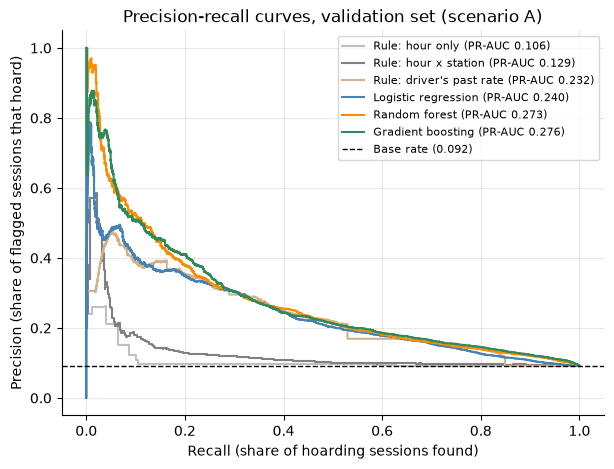

In [28]:
# one curve per rule and model; the base rate is a flat line at the share of hoarding
colors = {"Rule: hour only": "silver",
          "Rule: hour x station": "grey",
          "Rule: driver's past rate": "tan",
          "Logistic regression": "steelblue",
          "Random forest": "darkorange",
          "Gradient boosting": "seagreen"}

fig, ax = plt.subplots(figsize=(7, 5))
for name, color in colors.items():
    precision, recall, _ = precision_recall_curve(y_val, all_probs[name])
    
    # steps, because PR-AUC (average precision) is the area under this step curve
    ax.plot(recall, precision, drawstyle="steps-post", color=color,
            label=f"{name} (PR-AUC {results[name]['PR-AUC']:.3f})")

base_rate = y_val.mean()
ax.axhline(base_rate, color="black", linestyle="--", linewidth=1, label=f"Base rate ({base_rate:.3f})")

ax.set_title("Precision-recall curves, validation set (scenario A)")
ax.set_xlabel("Recall (share of hoarding sessions found)")
ax.set_ylabel("Precision (share of flagged sessions that hoard)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

The three models and the driver's past-rate rule stay well above the two rules without driver information at almost every recall. The past-rate rule follows logistic regression closely from a recall of about 0.1 onwards. Random forest and gradient boosting are ahead of both only among the riskiest sessions, up to a recall of about 0.3, and after that the four curves almost coincide; this is where their PR-AUC gain over the past-rate rule comes from. The spikes near recall 0 come from a handful of sessions and should not be read into.

**Uncertainty of the PR-AUC.** Sessions of the same driver are not independent, so we resample drivers rather than sessions: each of the 1,000 resamples draws drivers with replacement and keeps all their validation sessions. Each session without a known driver (missing user ID or the shared account 0) is its own group. The table gives the 95% percentile interval; 1,000 resamples is the usual choice for percentile intervals. The interval of each model is wide, likely because a few drivers with many sessions move the PR-AUC a lot. Every model is scored on the same resamples, so these swings largely cancel out in the difference between gradient boosting and random forest, and its interval shows whether the gap between them is real. The same is done for the gain of logistic regression and gradient boosting over the hour and station rule, and for the gain of gradient boosting over the driver's past-rate rule.

In [29]:
# groups: one per known driver
# sessions of the same driver are not independent, so the driver is the unit we resample
# every session without a known driver (missing ID or the shared account 0) is its own group
known_driver = val_A_f["user_id"].notna() & (val_A_f["user_id"] != "0")
group = np.where(known_driver, "u" + val_A_f["user_id"].astype(str), "s" + val_A_f.index.astype(str))

# positions of the sessions of each group, in the order groupby gives
rows_by_group = pd.Series(np.arange(len(group))).groupby(group).indices
group_rows = list(rows_by_group.values())
print(f"Groups: {len(group_rows):,} ({known_driver.sum():,} sessions from known drivers)")


# resample drivers
N_BOOT = 1000
rng = np.random.default_rng(42)
boot_models = ["Rule: hour only",
               "Rule: hour x station",
               "Rule: driver's past rate",
               "Logistic regression",
               "Random forest",
               "Gradient boosting"]
y_arr = y_val.to_numpy()
boot_scores = {name: [] for name in boot_models}

for i in range(N_BOOT):  # one resample per round
    picked = rng.integers(0, len(group_rows), len(group_rows))
    idx = np.concatenate([group_rows[g] for g in picked])  # same resample for every model
    for name in boot_models:
        boot_scores[name].append(average_precision_score(y_arr[idx], all_probs[name][idx]))


# 95% percentile intervals
boot_table = pd.DataFrame(boot_scores)
boot_table["GB - RF"] = boot_table["Gradient boosting"] - boot_table["Random forest"]
# gains over the best rule, on the same resamples
boot_table["LR - Rule (hour x station)"] = boot_table["Logistic regression"] - boot_table["Rule: hour x station"]
boot_table["GB - Rule (hour x station)"] = boot_table["Gradient boosting"] - boot_table["Rule: hour x station"]
# gain over the rule that uses only the driver's past hoarding rate
boot_table["GB - Rule (past rate)"] = boot_table["Gradient boosting"] - boot_table["Rule: driver's past rate"]

ci = boot_table.quantile([0.025, 0.975]).T
ci.columns = ["2.5%", "97.5%"]
point = [results[name]["PR-AUC"] for name in boot_models]
point.append(results["Gradient boosting"]["PR-AUC"] - results["Random forest"]["PR-AUC"])
point.append(results["Logistic regression"]["PR-AUC"] - results["Rule: hour x station"]["PR-AUC"])
point.append(results["Gradient boosting"]["PR-AUC"] - results["Rule: hour x station"]["PR-AUC"])
point.append(results["Gradient boosting"]["PR-AUC"] - results["Rule: driver's past rate"]["PR-AUC"])
ci.insert(0, "PR-AUC", point)
ci.round(3)

Groups: 6,778 (33,710 sessions from known drivers)


,PR-AUC,2.5%,97.5%
Rule: hour only,0.106,0.086,0.141
Rule: hour x station,0.129,0.094,0.183
Rule: driver's past rate,0.232,0.182,0.290
Logistic regression,0.240,0.181,0.314
Random forest,0.273,0.200,0.349
Gradient boosting,0.276,0.204,0.353
GB - RF,0.002,-0.008,0.015
LR - Rule (hour x station),0.111,0.079,0.144
GB - Rule (hour x station),0.146,0.104,0.180
GB - Rule (past rate),0.044,0.015,0.069


**Number of trees.** For the chosen gradient boosting setting, we add trees 50 at a time, up to twice the chosen number, and record the validation PR-AUC after each step (`warm_start` keeps the trees already fitted). This only checks that the chosen number is reasonable; it is not used to tune it.

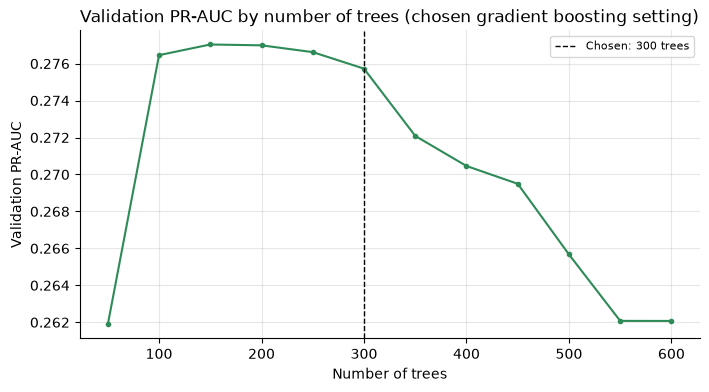

PR-AUC at the chosen number of trees: 0.2757 | best on the curve: 0.2770 at 150 trees


In [30]:
# prepare the data once
# warm_start adds trees to a fitted model, which only works on the model itself, not inside the pipeline
gb_params = best["Gradient boosting"]["params"]
chosen = gb_params["max_iter"]
prep = clone(gb_prep).fit(X_fit)
X_fit_prep = prep.transform(X_fit)
X_val_prep = prep.transform(X_val)

# grow the chosen model 50 trees at a time, up to twice the chosen number
gb_check = HistGradientBoostingClassifier(categorical_features=[0], early_stopping=False,
                                          warm_start=True, random_state=42, **gb_params)
steps = list(range(50, 2 * chosen + 1, 50))
curve = []
for n in steps:
    gb_check.set_params(max_iter=n).fit(X_fit_prep, y_fit)  # keeps the trees already fitted
    prob = gb_check.predict_proba(X_val_prep)[:, 1]
    curve.append(average_precision_score(y_val, prob))

# plot
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(steps, curve, color="seagreen", marker="o", markersize=3)
ax.axvline(chosen, color="black", linestyle="--", linewidth=1, label=f"Chosen: {chosen} trees")
ax.set_title("Validation PR-AUC by number of trees (chosen gradient boosting setting)")
ax.set_xlabel("Number of trees")
ax.set_ylabel("Validation PR-AUC")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

at_chosen = curve[steps.index(chosen)]
best_n = steps[int(np.argmax(curve))]
print(f"PR-AUC at the chosen number of trees: {at_chosen:.4f} | best on the curve: {max(curve):.4f} at {best_n} trees")

Note the narrow vertical scale: the whole curve spans only 0.015. The validation PR-AUC rises to a flat region between about 100 and 250 trees (around 0.277) and falls clearly after 300, as the model begins to overfit. The chosen 300 trees sit just past that region, about 0.001 below its top. We keep them: the gap is too small to matter, and picking the number of trees from this curve would be one more choice tuned on the validation set. The final model is trained on fit plus validation, about 25% more data, which usually supports more trees before overfitting, so 300 trees should be at least as safe there.

**Model choice.** All three models clearly beat the rules that do not know the driver: their PR-AUC is between 0.24 and 0.28, against 0.13 for the hour and station rule, 0.11 for the hour alone and 0.09 for the base rate, and across the same driver resamples the gain over the hour and station rule stays above zero (0.079 to 0.144 for logistic regression, 0.104 to 0.180 for gradient boosting). The hour adds little on its own and the station adds more. The driver's past hoarding rate on its own already reaches 0.23, so most of the signal comes from the driver. Gradient boosting still adds 0.044 over it (0.015 to 0.069 across the driver resamples), while among the 10% riskiest sessions the two are level (29% of them hoard in both cases).

Gradient boosting (0.276, learning rate 0.05, depth 4, 300 trees, balanced class weights) and random forest (0.273, depth 20, at least 5 sessions per leaf, no class weights) come out on top. With drivers resampled, the 95% interval of the difference between them runs from -0.008 to 0.015 and includes zero, so the two cannot be told apart on the validation set. We keep gradient boosting because it trains several times faster (see the training times printed with the grid) and uses the station as a native categorical feature. Among the 10% of sessions that gradient boosting rates as most risky, about 29% hoard, three times the base rate, and these sessions contain about a third of all hoarding in the validation set.

The grids were widened to check that the winners are not at their edges: for gradient boosting, learning rate 0.05 lies between 0.02 and 0.1 and depth 4 between 3 and 6; for logistic regression, C = 0.01 lies between 0.001 and 10. The best random forest still uses the smallest leaf size in its grid (5 sessions), but its top settings differ by less than 0.001 and it already matches gradient boosting, so we did not search further. These validation numbers come from the best of several settings chosen on the same data, so they are slightly optimistic; the final results come from the test set.


In [31]:

# STEP 1 — Smooth driver history
# Compare k values using the validation set only.

def smooth_history(train, *others, k):
    m = train["hoarding"].mean()
    filled = []

    for d in (train, *others):
        out = d.copy()

        n = out["prev_sessions"]
        h = out["prev_hoardings"]

        if k == 0:
            # Original rate; use training mean for no history
            rate = h / n.where(n > 0)
            rate = rate.fillna(m)
        else:
            # Smoothed historical rate
            rate = (h + k * m) / (n + k)

        out["prev_hoarding_rate"] = rate
        filled.append(out)

    return m, filled


# Best gradient boosting setting from the grid (Section 4.4)
gb_params = best["Gradient boosting"]["params"]

smoothing_results = []

for k in [0, 2, 5, 10]:

    m, (fit_k, val_k) = smooth_history(
        fit_A, val_A, k=k
    )

    model = make_model(
        "Gradient boosting", gb_params
    )

    model.fit(
        fit_k[ALL_FEATURES],
        fit_k["hoarding"]
    )

    prob = model.predict_proba(
        val_k[ALL_FEATURES]
    )[:, 1]

    score = average_precision_score(
        val_k["hoarding"], prob
    )

    smoothing_results.append({
        "k": k,
        "Validation PR-AUC": score
    })

smoothing_table = pd.DataFrame(smoothing_results)

display(smoothing_table)

best_k = int(
    smoothing_table.loc[
        smoothing_table["Validation PR-AUC"].idxmax(),
        "k"
    ]
)

print("Best smoothing k:", best_k)


,k,Validation PR-AUC
0,0,0.275726
1,2,0.269524
2,5,0.272343
3,10,0.270766


Best smoothing k: 0


**Driver history smoothing.** We evaluated smoothing parameters k = 0, 2, 5, and 10 using validation PR-AUC. The best result was obtained with k = 0 (PR-AUC = 0.2757). Since none of the tested smoothing values improved predictive performance, we retained the original driver history rate for subsequent analysis.

In [32]:

# STEP 2 — With vs Without Driver History
# Same gradient boosting settings and temporal validation split.

# Model 1: With driver history
model_with = make_model(
    "Gradient boosting",
    best["Gradient boosting"]["params"]
)

model_with.fit(
    fit_A_f[ALL_FEATURES],
    fit_A_f["hoarding"]
)

prob_with = model_with.predict_proba(
    val_A_f[ALL_FEATURES]
)[:, 1]


# Model 2: Without driver history
# A separate preprocessing pipeline is required.

gb_prep_base = ColumnTransformer([
    ("station", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=np.nan
    ), ["station"]),
    ("rest", "passthrough",
     ["start_hour", "is_weekend", "paid_period"])
])

model_without = Pipeline([
    ("prep", gb_prep_base),
    ("clf", HistGradientBoostingClassifier(
        categorical_features=[0],
        early_stopping=False,
        random_state=42,
        **best["Gradient boosting"]["params"]
    ))
])

model_without.fit(
    fit_A_f[BASE_FEATURES],
    fit_A_f["hoarding"]
)

prob_without = model_without.predict_proba(
    val_A_f[BASE_FEATURES]
)[:, 1]


# Compare both models across validation groups.
groups = {
    "All sessions": np.ones(len(val_A_f), dtype=bool),
    "Has history": (val_A_f["has_history"] == 1).to_numpy(),
    "No history": (val_A_f["has_history"] == 0).to_numpy()
}

comparison = []

# Threshold of each model chosen on all validation sessions,
# then used unchanged in the history groups.
all_thresholds = {
    "With history": evaluate(
        val_A_f["hoarding"], prob_with
    )["threshold"],
    "Without history": evaluate(
        val_A_f["hoarding"], prob_without
    )["threshold"]
}

for group_name, mask in groups.items():
    for model_name, probabilities in [
        ("With history", prob_with),
        ("Without history", prob_without)
    ]:
        metrics = evaluate(
            val_A_f["hoarding"].to_numpy()[mask],
            probabilities[mask],
            threshold=all_thresholds[model_name]
        )

        comparison.append({
            "Group": group_name,
            "Model": model_name,
            "Sessions": int(mask.sum()),
            "Base rate": val_A_f["hoarding"].to_numpy()[mask].mean(),
            "PR-AUC": metrics["PR-AUC"],
            "ROC-AUC": metrics["ROC-AUC"],
            "F1": metrics["F1"],
            "Precision": metrics["precision"],
            "Recall": metrics["recall"],
            "Top 10% precision": metrics["top10% precision"],
            "Top 10% recall": metrics["top10% recall"]
        })

comparison_table = pd.DataFrame(comparison)

display(comparison_table.round(4))


,Group,Model,Sessions,Base rate,PR-AUC,ROC-AUC,F1,Precision,Recall,Top 10% precision,Top 10% recall
0,All sessions,With history,34403,0.0919,0.2757,0.7398,0.3080,0.2643,0.3691,0.2922,0.3178
1,All sessions,Without history,34403,0.0919,0.1510,0.5839,0.1904,0.1269,0.3808,0.1663,0.1809
2,Has history,With history,30443,0.0926,0.2952,0.7585,0.3271,0.2805,0.3923,0.3095,0.3342
3,Has history,Without history,30443,0.0926,0.1565,0.5887,0.1931,0.1289,0.3852,0.1695,0.1830
4,No history,With history,3960,0.0866,0.1075,0.5491,0.1497,0.1292,0.1778,0.1313,0.1516
5,No history,Without history,3960,0.0866,0.1042,0.5440,0.1682,0.1113,0.3440,0.1212,0.1399


**Driver history comparison.** Including driver history substantially improved the gradient boosting model's predictive performance. Validation PR-AUC increased from 0.1510 to 0.2757 across all sessions. The improvement was particularly strong for drivers with previous charging sessions (0.1565 to 0.2952), while the difference for drivers without history was minimal (0.1042 to 0.1075). Therefore, driver history features were retained for the final model. On the validation set, the base rates make the gap clearer: for drivers without history the PR-AUC is only 1.2 times the base rate (0.108 against 0.087), against 3.2 times for drivers with history. With one threshold for all drivers, the model flags just 18% of their hoarding sessions.

In [33]:

# STEP 3 — Select threshold on validation data

validation_metrics = evaluate(
    val_A_f["hoarding"],
    prob_with
)

selected_threshold = validation_metrics["threshold"]

print(f"Selected threshold: {selected_threshold:.4f}")
print(f"Validation PR-AUC: {validation_metrics['PR-AUC']:.4f}")
print(f"Validation Precision: {validation_metrics['precision']:.4f}")
print(f"Validation Recall: {validation_metrics['recall']:.4f}")
print(f"Validation F1: {validation_metrics['F1']:.4f}")

# share of validation sessions flagged with this threshold (the test share is shown in step 4)
print(f"Sessions flagged on validation: {(prob_with >= selected_threshold).mean() * 100:.1f}%")

Selected threshold: 0.4916
Validation PR-AUC: 0.2757
Validation Precision: 0.2643
Validation Recall: 0.3691
Validation F1: 0.3080
Sessions flagged on validation: 12.8%


**Threshold.** A session is flagged when its predicted probability is at least 0.492, the threshold with the best F1 on the validation set. The same threshold is used unchanged on the test set, although it was chosen on the model trained on the fit set and the final model is refitted on fit plus validation. The share of sessions it flags stays close (12.8% on validation, 11.7% on test), so the two models give probabilities on a similar scale.

In [34]:

# STEP 4 — Final Test Evaluation
# Keep all decisions fixed from validation.

# Recalculate historical rates using the final training mean.
_, (train_final, test_final) = smooth_history(
    train_A, test_A, k=best_k
)

# Build and train the selected gradient boosting model.
final_model = make_model(
    "Gradient boosting",
    best["Gradient boosting"]["params"]
)

final_model.fit(
    train_final[ALL_FEATURES],
    train_final["hoarding"]
)

# Predict on the held-out test set.
y_test = test_final["hoarding"]

test_prob = final_model.predict_proba(
    test_final[ALL_FEATURES]
)[:, 1]

# Apply the threshold selected on validation.
test_metrics = evaluate(
    y_test,
    test_prob,
    threshold=selected_threshold
)

print("FINAL TEST RESULTS")
print(f"Test sessions: {len(y_test):,}")
print(f"Test hoarding rate: {y_test.mean():.4f}")
print(f"Threshold: {test_metrics['threshold']:.4f}")

for metric in [
    "PR-AUC",
    "ROC-AUC",
    "precision",
    "recall",
    "F1",
    "top10% precision",
    "top10% recall"
]:
    print(f"{metric}: {test_metrics[metric]:.4f}")

# share of test sessions flagged with the validation threshold
print(f"Sessions flagged on test: {(test_prob >= selected_threshold).mean() * 100:.1f}%")


# Driver bootstrap of the test PR-AUC and F1 (as in Section 4.4).
# Sessions without a known driver are their own group.
known_test = (
    test_final["user_id"].notna()
    & (test_final["user_id"] != "0")
)

group_test = np.where(
    known_test,
    "u" + test_final["user_id"].astype(str),
    "s" + test_final.index.astype(str)
)

group_rows_test = list(
    pd.Series(np.arange(len(group_test)))
    .groupby(group_test)
    .indices.values()
)

y_test_arr = y_test.to_numpy()
flag_test = test_prob >= selected_threshold

rng_test = np.random.default_rng(42)

boot_test = {
    "PR-AUC": [],
    "F1": []
}

for i in range(N_BOOT):
    picked = rng_test.integers(
        0, len(group_rows_test), len(group_rows_test)
    )
    idx = np.concatenate(
        [group_rows_test[g] for g in picked]
    )

    boot_test["PR-AUC"].append(
        average_precision_score(y_test_arr[idx], test_prob[idx])
    )
    boot_test["F1"].append(
        f1_score(y_test_arr[idx], flag_test[idx])
    )

test_ci = pd.DataFrame(boot_test).quantile([0.025, 0.975]).T
test_ci.columns = ["2.5%", "97.5%"]
test_ci.insert(0, "Test", [
    test_metrics["PR-AUC"],
    test_metrics["F1"]
])

print(f"PR-AUC / test base rate: {test_metrics['PR-AUC'] / y_test.mean():.2f}")
display(test_ci.round(4))

# baseline without ML on the test set: the driver's past hoarding rate (training mean for drivers without history)
past_rate_test = test_final["prev_hoarding_rate"].to_numpy()
rule_test = evaluate(y_test_arr, past_rate_test)
print(f"Rule (driver's past rate): PR-AUC {rule_test['PR-AUC']:.4f}, "
      f"top10% precision {rule_test['top10% precision']:.4f}, top10% recall {rule_test['top10% recall']:.4f}")

# driver bootstrap of model - rule, on the same resamples as above
rng_rule = np.random.default_rng(42)
boot_rule = []
for i in range(N_BOOT):  # one resample per round
    picked = rng_rule.integers(0, len(group_rows_test), len(group_rows_test))
    idx = np.concatenate([group_rows_test[g] for g in picked])
    boot_rule.append(average_precision_score(y_test_arr[idx], test_prob[idx])
                     - average_precision_score(y_test_arr[idx], past_rate_test[idx]))
low, high = np.percentile(boot_rule, [2.5, 97.5])
print(f"Model - rule PR-AUC: {test_metrics['PR-AUC'] - rule_test['PR-AUC']:.4f} (95% interval {low:.4f} to {high:.4f})")

# where the gain comes from: drivers with and without history
has_hist = test_final["has_history"].to_numpy() == 1
by_history = []
for label, mask in [("With history", has_hist), ("Without history", ~has_hist)]:
    by_history.append({"Group": label, "Sessions": int(mask.sum()), "Base rate": y_test_arr[mask].mean(),
                       "Model PR-AUC": average_precision_score(y_test_arr[mask], test_prob[mask]),
                       "Rule PR-AUC": average_precision_score(y_test_arr[mask], past_rate_test[mask])})
display(pd.DataFrame(by_history).round(3))

FINAL TEST RESULTS
Test sessions: 73,721
Test hoarding rate: 0.0794
Threshold: 0.4916
PR-AUC: 0.2778
ROC-AUC: 0.7641
precision: 0.2722
recall: 0.4002
F1: 0.3240
top10% precision: 0.2923
top10% recall: 0.3681
Sessions flagged on test: 11.7%
PR-AUC / test base rate: 3.50


,Test,2.5%,97.5%
PR-AUC,0.2778,0.2386,0.3183
F1,0.3240,0.2903,0.3571


Rule (driver's past rate): PR-AUC 0.2259, top10% precision 0.2842, top10% recall 0.3579
Model - rule PR-AUC: 0.0519 (95% interval 0.0355 to 0.0684)


,Group,Sessions,Base rate,Model PR-AUC,Rule PR-AUC
0,With history,64438,0.080,0.295,0.244
1,Without history,9283,0.076,0.131,0.076


**Final test evaluation.** The selected gradient boosting model was evaluated on 73,721 held-out charging sessions using the validation-selected threshold of 0.4916. The model achieved a PR-AUC of 0.2778, ROC-AUC of 0.7641, precision of 0.2722, recall of 0.4002, and F1-score of 0.3240. With 7.9% of test sessions hoarding, the PR-AUC is about 3.5 times what a random ranking would give. A driver bootstrap puts the PR-AUC between 0.239 and 0.318 and the F1 between 0.290 and 0.357 (95% intervals). The driver's past hoarding rate alone reaches 0.226 on the test set. The model's gain over it, 0.052 (0.036 to 0.068), appears both for drivers with history (0.295 against 0.244) and for drivers without (0.131 against a base rate of 0.076). Test performance was comparable to validation performance, suggesting reasonable generalization to the held-out period. However, the relatively low precision indicates that predictions should be used cautiously when considering targeted interventions.

In [35]:

# STEP 5 — Scenario A vs Scenario B
# Reporting comparison only: no further model selection.

FEATURES_B = [
    feature for feature in ALL_FEATURES
    if feature != "paid_period"
]

# Check chronological boundaries.
print("Scenario A training ends:", train_A["start"].max())
print("Scenario B test begins:", test_B["start"].min())

if train_A["start"].max() >= test_B["start"].min():
    print("WARNING: Training and test periods overlap!")
else:
    print("Chronological separation confirmed.")

# Scenario A: use the already trained final model.

_, (train_A_for_B, test_B_for_A) = smooth_history(
    train_A, test_B, k=best_k
)

prob_A_on_B = final_model.predict_proba(
    test_B_for_A[ALL_FEATURES]
)[:, 1]

# Scenario B: exclude paid_period from the pipeline.
prep_B = ColumnTransformer([
    ("station", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=np.nan
    ), ["station"]),
    ("rest", "passthrough", [
        "start_hour",
        "prev_sessions",
        "prev_hoarding_rate",
        "is_weekend",
        "has_history"
    ])
])

# pipeline for scenario B with a given setting
def make_model_B(params):
    clf = HistGradientBoostingClassifier(categorical_features=[0], early_stopping=False,
                                         random_state=42, **params)
    return Pipeline([("prep", clone(prep_B)), ("clf", clf)])


# B chooses its own hyperparameters on validation B
# fill value = hoarding rate of fit B, used for drivers without history
fill_B_s, (fit_B_s, val_B_s) = smooth_history(fit_B, val_B, k=best_k)

# A grid widened towards simpler models: the first winner was at its edge (learning rate 0.1, depth 3)
trees_for_lr_B = {0.02: 750, 0.05: 300, 0.1: 150, 0.2: 75}
grid_B = [{"learning_rate": lr, "max_iter": trees_for_lr_B[lr], "max_depth": d, "class_weight": w}
          for lr in [0.02, 0.05, 0.1, 0.2]
          for d in [1, 2, 3, 4, 6]
          for w in [None, "balanced"]]

# train every setting on fit B, score it on validation B and keep the best
grid_rows_B = []
best_score_B = -1
for params in grid_B:
    model = make_model_B(params).fit(fit_B_s[FEATURES_B], fit_B_s["hoarding"])
    prob = model.predict_proba(val_B_s[FEATURES_B])[:, 1]
    score = average_precision_score(val_B_s["hoarding"], prob)
    grid_rows_B.append({**params, "PR-AUC": score})
    if score > best_score_B:
        best_score_B, params_B, prob_val_B = score, params, prob

# best validation PR-AUC for each depth (rows) and learning rate (columns)
grid_table_B = pd.DataFrame(grid_rows_B)
best_by_depth_lr = grid_table_B.pivot_table(index="max_depth", columns="learning_rate",
                                            values="PR-AUC", aggfunc="max")
display(best_by_depth_lr.round(4))
print("Chosen for B:", params_B)
print("Chosen for A:", best["Gradient boosting"]["params"])

# threshold for B, chosen the same way as for A: the best-F1 cut on validation B
threshold_B = evaluate(val_B_s["hoarding"], prob_val_B)["threshold"]
print(f"Threshold A (validation A): {selected_threshold:.4f}")
print(f"Threshold B (validation B): {threshold_B:.4f}")

# final model B: refit on fit + validation B
fill_B_final_s, (train_B_s, test_B_s) = smooth_history(train_B, test_B, k=best_k)

model_B = make_model_B(params_B).fit(train_B_s[FEATURES_B], train_B_s["hoarding"])

prob_B_on_B = model_B.predict_proba(
    test_B_s[FEATURES_B]
)[:, 1]

# Compare on the same test sessions; each model uses its own threshold.
scenario_rows = []

for name, probs, threshold in [
    ("A - All training sessions", prob_A_on_B, selected_threshold),
    ("B - Paid-period training", prob_B_on_B, threshold_B)
]:
    metrics = evaluate(
        test_B["hoarding"],
        probs,
        threshold=threshold
    )

    scenario_rows.append({
        "Scenario": name,
        "Threshold": threshold,
        "PR-AUC": metrics["PR-AUC"],
        "ROC-AUC": metrics["ROC-AUC"],
        "Precision": metrics["precision"],
        "Recall": metrics["recall"],
        "F1": metrics["F1"],
        "Top 10% precision": metrics["top10% precision"],
        "Top 10% recall": metrics["top10% recall"]
    })

scenario_comparison = pd.DataFrame(scenario_rows)
display(scenario_comparison.round(4))


# driver bootstrap of the difference B - A on the same test sessions, as in Section 4.4
# groups: one per known driver; every session without a known driver is its own group
known_B = test_B_s["user_id"].notna() & (test_B_s["user_id"] != "0")
group_B = np.where(known_B, "u" + test_B_s["user_id"].astype(str), "s" + test_B_s.index.astype(str))
group_rows_B = list(pd.Series(np.arange(len(group_B))).groupby(group_B).indices.values())

# sessions flagged by each model at its own threshold
y_B = test_B["hoarding"].to_numpy()
flag_A = prob_A_on_B >= selected_threshold
flag_B = prob_B_on_B >= threshold_B

# resample drivers; both models are scored on the same resample
rng_B = np.random.default_rng(42)
boot_B = {"PR-AUC B - A": [], "F1 B - A": []}

for i in range(N_BOOT):  # one resample per round
    picked = rng_B.integers(0, len(group_rows_B), len(group_rows_B))
    idx = np.concatenate([group_rows_B[g] for g in picked])
    pr_auc_A = average_precision_score(y_B[idx], prob_A_on_B[idx])
    pr_auc_B = average_precision_score(y_B[idx], prob_B_on_B[idx])
    boot_B["PR-AUC B - A"].append(pr_auc_B - pr_auc_A)
    boot_B["F1 B - A"].append(f1_score(y_B[idx], flag_B[idx]) - f1_score(y_B[idx], flag_A[idx]))

# difference on the whole test set and its 95% percentile interval
ci_B = pd.DataFrame(boot_B).quantile([0.025, 0.975]).T
ci_B.columns = ["2.5%", "97.5%"]
pr_auc_diff = average_precision_score(y_B, prob_B_on_B) - average_precision_score(y_B, prob_A_on_B)
f1_diff = f1_score(y_B, flag_B) - f1_score(y_B, flag_A)
ci_B.insert(0, "Difference", [pr_auc_diff, f1_diff])
display(ci_B.round(3))

# A new: all sessions (free and paid), but with the same cut-off dates and validation set as B,
# so the only difference between A new and B is the free-period data
val_start = val_B["start"].min()
test_start = test_B["start"].min()
fit_An = ev[ev["start"] < val_start]
train_An = ev[ev["start"] < test_start]
fill_An, (fit_An_s, val_An_s) = smooth_history(fit_An, val_B, k=best_k)
print(f"A new fit: {fit_An['start'].min().date()} to {fit_An['start'].max().date()} "
      f"({len(fit_An):,} sessions, {fit_An['paid_period'].mean() * 100:.0f}% paid)")


# pipeline for A new with a given setting (all features, including paid_period)
def make_model_An(params):
    clf = HistGradientBoostingClassifier(categorical_features=[0], early_stopping=False,
                                         random_state=42, **params)
    return Pipeline([("prep", clone(gb_prep)), ("clf", clf)])


# B's grid plus learning rate 0.01 with 1500 trees, because the first winner sat at the lowest rate (0.02)
grid_An = grid_B + [{"learning_rate": 0.01, "max_iter": 1500, "max_depth": d, "class_weight": w}
                    for d in [1, 2, 3, 4, 6]
                    for w in [None, "balanced"]]

# train every setting on fit A new, score it on validation B and keep the best
grid_rows_An = []
best_score_An = -1
for params in grid_An:
    model = make_model_An(params).fit(fit_An_s[ALL_FEATURES], fit_An_s["hoarding"])
    prob = model.predict_proba(val_An_s[ALL_FEATURES])[:, 1]
    score = average_precision_score(val_An_s["hoarding"], prob)
    grid_rows_An.append({**params, "PR-AUC": score})
    if score > best_score_An:
        best_score_An, params_An, prob_val_An = score, params, prob

# best validation PR-AUC for each depth (rows) and learning rate (columns)
best_by_depth_lr_An = pd.DataFrame(grid_rows_An).pivot_table(index="max_depth", columns="learning_rate",
                                                             values="PR-AUC", aggfunc="max")
display(best_by_depth_lr_An.round(4))
print("Chosen for A new:", params_An)

# threshold on validation B; final model refitted on everything before the test of B
threshold_An = evaluate(val_An_s["hoarding"], prob_val_An)["threshold"]
print(f"Threshold A new (validation B): {threshold_An:.4f}")
fill_An_final, (train_An_s, test_An_s) = smooth_history(train_An, test_B, k=best_k)
model_An = make_model_An(params_An).fit(train_An_s[ALL_FEATURES], train_An_s["hoarding"])
prob_An_on_B = model_An.predict_proba(test_An_s[ALL_FEATURES])[:, 1]

# the three models on the same test sessions
three_rows = []
for name, probs, threshold in [("A old: all data, training ends Jul 2018", prob_A_on_B, selected_threshold),
                               ("A new: all data, same dates as B", prob_An_on_B, threshold_An),
                               ("B: paid period only", prob_B_on_B, threshold_B)]:
    metrics = evaluate(y_B, probs, threshold=threshold)
    three_rows.append({"Model": name, "PR-AUC": metrics["PR-AUC"],
                       "ROC-AUC": metrics["ROC-AUC"], "F1": metrics["F1"]})
display(pd.DataFrame(three_rows).round(3))

# driver bootstrap: B - A new (free-period data) and A new - A old (later training cut-off)
rng_An = np.random.default_rng(42)
boot_An = {"B - A new": [], "A new - A old": []}
for i in range(N_BOOT):  # one resample per round
    picked = rng_An.integers(0, len(group_rows_B), len(group_rows_B))
    idx = np.concatenate([group_rows_B[g] for g in picked])
    pr_auc_old = average_precision_score(y_B[idx], prob_A_on_B[idx])
    pr_auc_new = average_precision_score(y_B[idx], prob_An_on_B[idx])
    pr_auc_B = average_precision_score(y_B[idx], prob_B_on_B[idx])
    boot_An["B - A new"].append(pr_auc_B - pr_auc_new)
    boot_An["A new - A old"].append(pr_auc_new - pr_auc_old)

# difference on the whole test set and its 95% percentile interval
ci_An = pd.DataFrame(boot_An).quantile([0.025, 0.975]).T
ci_An.columns = ["2.5%", "97.5%"]
pr_auc_all = {name: average_precision_score(y_B, probs)
              for name, probs in [("old", prob_A_on_B), ("new", prob_An_on_B), ("B", prob_B_on_B)]}
ci_An.insert(0, "PR-AUC difference", [pr_auc_all["B"] - pr_auc_all["new"], pr_auc_all["new"] - pr_auc_all["old"]])
display(ci_An.round(3))


Scenario A training ends: 2018-07-31 08:15:00
Scenario B test begins: 2019-06-16 18:38:00
Chronological separation confirmed.


learning_rate,0.02,0.05,0.10,0.20
max_depth,,,,
1,0.2621,0.2621,0.2619,0.2615
2,0.2766,0.2771,0.2777,0.2783
3,0.2747,0.2730,0.2756,0.2712
4,0.2716,0.2741,0.2692,0.2726
6,0.2690,0.2681,0.2662,0.2658


Chosen for B: {'learning_rate': 0.2, 'max_iter': 75, 'max_depth': 2, 'class_weight': None}
Chosen for A: {'learning_rate': 0.05, 'max_iter': 300, 'max_depth': 4, 'class_weight': 'balanced'}
Threshold A (validation A): 0.4916
Threshold B (validation B): 0.1991


,Scenario,Threshold,PR-AUC,ROC-AUC,Precision,Recall,F1,Top 10% precision,Top 10% recall
0,A - All training sessions,0.4916,0.2611,0.7642,0.2630,0.3628,0.3049,0.2622,0.3632
1,B - Paid-period training,0.1991,0.2731,0.7738,0.3278,0.2789,0.3014,0.2678,0.3708


,Difference,2.5%,97.5%
PR-AUC B - A,0.012,-0.001,0.028
F1 B - A,-0.004,-0.025,0.014


A new fit: 2011-07-29 to 2019-02-12 (195,336 sessions, 33% paid)


learning_rate,0.01,0.02,0.05,0.10,0.20
max_depth,,,,,
1,0.2380,0.2381,0.2382,0.2383,0.2367
2,0.2615,0.2618,0.2621,0.2613,0.2592
3,0.2747,0.2740,0.2761,0.2728,0.2737
4,0.2868,0.2877,0.2856,0.2859,0.2822
6,0.2861,0.2855,0.2870,0.2802,0.2785


Chosen for A new: {'learning_rate': 0.02, 'max_iter': 750, 'max_depth': 4, 'class_weight': None}
Threshold A new (validation B): 0.1818


,Model,PR-AUC,ROC-AUC,F1
0,"A old: all data, training ends Jul 2018",0.261,0.764,0.305
1,"A new: all data, same dates as B",0.277,0.776,0.305
2,B: paid period only,0.273,0.774,0.301


,PR-AUC difference,2.5%,97.5%
B - A new,-0.004,-0.014,0.007
A new - A old,0.016,0.006,0.026


**Scenario comparison.** Scenario B chooses its own hyperparameters on its validation set, as scenario A did in Section 4.4. We started from A's grid, but the first winner sat at its edge (learning rate 0.1, depth 3), so we added a learning rate of 0.2 with 75 trees and depths 1 and 2. Once the number of trees is adjusted, the learning rate barely matters: at depth 2 the four rates are within 0.002 of each other. Depth matters more. Validation PR-AUC rises as the trees get shallower, peaks at depth 2 and drops at depth 1, so the chosen depth is inside the grid. B seems to prefer simpler trees than A (depth 2 against 4, without class weights), perhaps because it has less than half as much training data.

Both models are scored on the same 34,364 paid-period test sessions (16 June 2019 to February 2020), each with the threshold chosen on its own validation set (0.492 for A, 0.199 for B). B ranks sessions slightly better (PR-AUC 0.273 against 0.261, ROC-AUC 0.774 against 0.764, with the driver bootstrap putting the difference between −0.001 and 0.028), and at the chosen thresholds the two are level (F1 0.301 against 0.305).

This comparison mixes two things: B leaves out the free period, but its training also ends almost a year later (June 2019 against July 2018). A third model, A new, separates them. It uses all sessions like A, but with B's cut-off dates and validation set, and chooses its own hyperparameters on B's grid, with a learning rate of 0.01 added because its winner first sat at the lowest rate. With the same dates, A new and B are level (PR-AUC 0.277 against 0.273, difference between −0.014 and 0.007), while A new is clearly ahead of A old (0.277 against 0.261, difference between 0.006 and 0.026). This gain comes mostly from the later training cut-off, although A new also had its own validation set and a larger grid. The free-period data therefore neither help nor hurt, while more recent training data seem to help. B was also chosen from a larger grid than A old, one more reason not to read much into its small lead.

,Feature,Importance,Std
5,prev_hoarding_rate,0.1905,0.0011
0,start_hour,0.0374,0.0019
4,prev_sessions,0.0332,0.0017
2,station,0.0226,0.0020
1,is_weekend,0.0034,0.0006
3,paid_period,0.0000,0.0000
6,has_history,0.0000,0.0000


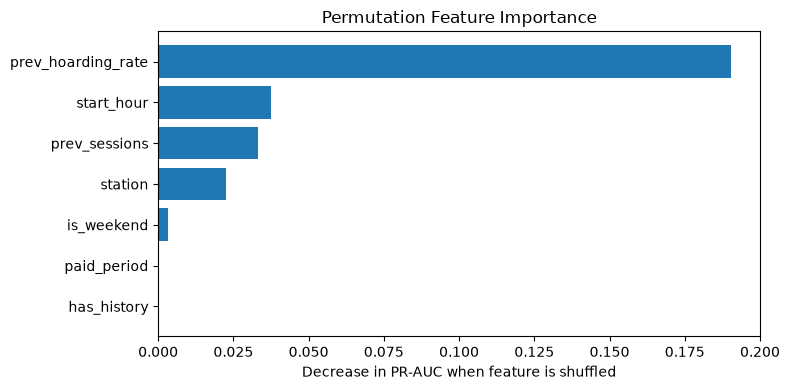

In [36]:

# STEP 6A — Permutation feature importance
# Use the final model and held-out test set.
# No model tuning is performed.

importance = permutation_importance(
    final_model,
    test_final[ALL_FEATURES],
    test_final["hoarding"],
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=1
)

importance_table = pd.DataFrame({
    "Feature": ALL_FEATURES,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

display(importance_table.round(4))

plt.figure(figsize=(8, 4))
plt.barh(
    importance_table["Feature"][::-1],
    importance_table["Importance"][::-1]
)
plt.xlabel("Decrease in PR-AUC when feature is shuffled")
plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.show()


**Feature importance.** We measured permutation importance on the test set as the drop in PR-AUC when one feature is shuffled, averaged over 10 repeats. The driver's past hoarding rate matters most (0.191), well ahead of the plug-in hour (0.037), the number of earlier sessions (0.033) and the station (0.023). Two features score exactly zero. paid_period is 1 for every test session, so shuffling it changes nothing; the effect of the fees shows in Section 4.2 instead, where hoarding fell after fees were introduced. has_history adds nothing beyond prev_sessions, since it is 1 exactly when prev_sessions is above zero. These scores show what the model relies on, not what causes hoarding.

In [37]:

# STEP 6B — Robustness check: hoarding > 2 hours
# Same model settings and smoothing k as the main analysis.

ev_2h = ev.copy()

# Use the two-hour target in the existing model functions.
ev_2h["hoarding"] = ev_2h["hoarding_2h"]

# Recalculate previous hoardings using only sessions
# that ended before the current session started.
ev_2h["prev_hoardings"] = 0

known_2h = (
    ev_2h["user_id"].notna()
    & (ev_2h["user_id"] != "0")
)

for user, g in ev_2h[known_2h].groupby("user_id"):
    ends = g.sort_values("end")
    end_times = ends["end"].values
    cumulative = ends["hoarding"].cumsum().values

    n_done = np.searchsorted(
        end_times, g["start"].values, side="right"
    )

    ev_2h.loc[g.index, "prev_hoardings"] = np.where(
        n_done > 0, cumulative[n_done - 1], 0
    )


# Recalculate the historical rate for the >2h target.
ev_2h["prev_hoarding_rate"] = (
    ev_2h["prev_hoardings"]
    / ev_2h["prev_sessions"].where(
        ev_2h["prev_sessions"] > 0
    )
)

# Verify that the original history feature was updated.
print(
    "Recalculated history for the >2h target:",
    ev_2h["prev_hoarding_rate"].notna().sum(),
    "sessions with known history"
)

# Same chronological split as the original analysis.
fit_2h, val_2h, test_2h = temporal_split(ev_2h)
train_2h = pd.concat([fit_2h, val_2h])

# Fill history using the corresponding training mean.
_, (fit_2h_f, val_2h_f) = smooth_history(
    fit_2h, val_2h, k=best_k
)

_, (train_2h_f, test_2h_f) = smooth_history(
    train_2h, test_2h, k=best_k
)

# Fit on the original fit period.
robust_val_model = make_model(
    "Gradient boosting",
    best["Gradient boosting"]["params"]
)

robust_val_model.fit(
    fit_2h_f[ALL_FEATURES],
    fit_2h_f["hoarding"]
)

val_prob_2h = robust_val_model.predict_proba(
    val_2h_f[ALL_FEATURES]
)[:, 1]

val_metrics_2h = evaluate(
    val_2h_f["hoarding"], val_prob_2h
)

# Retrain on fit + validation.
robust_final_model = make_model(
    "Gradient boosting",
    best["Gradient boosting"]["params"]
)

robust_final_model.fit(
    train_2h_f[ALL_FEATURES],
    train_2h_f["hoarding"]
)

test_prob_2h = robust_final_model.predict_proba(
    test_2h_f[ALL_FEATURES]
)[:, 1]

test_metrics_2h = evaluate(
    test_2h_f["hoarding"],
    test_prob_2h,
    threshold=val_metrics_2h["threshold"]
)

print("ROBUSTNESS CHECK — HOARDING > 2 HOURS")
print(f"Test sessions: {len(test_2h_f):,}")
print(f"Test base rate: {test_2h_f['hoarding'].mean():.4f}")
print(f"Validation threshold: {val_metrics_2h['threshold']:.4f}")

for metric in ["PR-AUC", "ROC-AUC", "precision", "recall", "F1"]:
    print(f"{metric}: {test_metrics_2h[metric]:.4f}")


Recalculated history for the >2h target: 217505 sessions with known history
ROBUSTNESS CHECK — HOARDING > 2 HOURS
Test sessions: 73,721
Test base rate: 0.0312
Validation threshold: 0.5844
PR-AUC: 0.2265
ROC-AUC: 0.8057
precision: 0.2283
recall: 0.3413
F1: 0.2736


In [38]:

# Verify that historical rates differ between the two targets.

mask = ev_2h["prev_sessions"] > 0

comparison_check = pd.DataFrame({
    "Original >1h rate": ev.loc[mask, "prev_hoarding_rate"],
    "New >2h rate": ev_2h.loc[mask, "prev_hoarding_rate"]
})

print("Sessions compared:", len(comparison_check))

print(
    "Sessions with different historical rates:",
    (
        comparison_check["Original >1h rate"]
        != comparison_check["New >2h rate"]
    ).sum()
)

display(comparison_check.head(10))


Sessions compared: 217505
Sessions with different historical rates: 134112


,Original >1h rate,New >2h rate
2,0.000000,0.000000
7,0.000000,0.000000
8,1.000000,0.000000
12,0.000000,0.000000
13,0.500000,0.000000
17,0.000000,0.000000
20,0.500000,0.500000
22,0.333333,0.000000
24,0.000000,0.000000
25,0.333333,0.333333


In [39]:

# Final consistency check for the >2h robustness model

rate_1h = test_final["prev_hoarding_rate"]
rate_2h = test_2h_f["prev_hoarding_rate"]

# Align observations by their original index
rates = pd.concat(
    [rate_1h.rename("rate_1h"),
     rate_2h.rename("rate_2h")],
    axis=1
)

print("Test sessions compared:", len(rates))
print(
    "Different model input rates:",
    (rates["rate_1h"] != rates["rate_2h"]).sum()
)
print(
    "Missing values in 2h model input:",
    test_2h_f["prev_hoarding_rate"].isna().sum()
)


Test sessions compared: 73721
Different model input rates: 45469
Missing values in 2h model input: 0


**Robustness check (>2 hours).** We repeated the analysis using a stricter definition of hoarding: more than two hours of idle time. The model keeps the settings chosen for the main target, since this checks the same model rather than building a new one. The test base rate decreased to 3.12%. The model achieved a PR-AUC of 0.2265, ROC-AUC of 0.8057, precision of 0.2283, recall of 0.3413, and F1-score of 0.2736. The PR-AUC is lower than for the >1h target, but so is the base rate (3.1% against 7.9%). Scaled between chance and a perfect model, the two targets give similar results (0.20 against 0.22), and the ROC-AUC, which does not depend on the base rate, is slightly higher for >2h (0.806 against 0.764). The model ranks severe hoarding as well as ordinary hoarding.

-----------------------------------------

## 4.5. Business impact of hoarding <a class="anchor" id="p4_5"></a>
  
[Back to TOC](#toc)

Size of the problem in 2018 and 2019, the two full years with all stations open.

In [40]:

# STEP 4.5A — Operational impact of hoarding
# Focus on 2018–2019, the two complete recent years.

recent = ev[
    ev["start"].dt.year.isin([2018, 2019])
].copy()

hoarding_sessions = recent[
    recent["hoarding"] == 1
].copy()

summary = pd.DataFrame({
    "Metric": [
        "Total charging sessions (2018–2019)",
        "Hoarding sessions (>1h, 2018–2019)",
        "Hoarding rate (%)",
        "Total idle hours (all sessions, 2018–2019)",
        "Idle hours in hoarding sessions (2018–2019)",
        "Daytime idle hours in hoarding sessions (2018–2019)",
        "Nighttime idle hours in hoarding sessions (2018–2019)"
    ],
    "Value": [
        len(recent),
        len(hoarding_sessions),
        100 * recent["hoarding"].mean(),
        recent["idle_hours"].sum(),
        hoarding_sessions["idle_hours"].sum(),
        hoarding_sessions.loc[
            hoarding_sessions["period"] == "Day",
            "idle_hours"
        ].sum(),
        hoarding_sessions.loc[
            hoarding_sessions["period"] == "Night",
            "idle_hours"
        ].sum()
    ]
})

# whole numbers, except the rate (one decimal)
summary["Value"] = [f"{v:.1f}" if metric == "Hoarding rate (%)" else f"{v:,.0f}"
                    for metric, v in zip(summary["Metric"], summary["Value"])]
display(summary)


,Metric,Value
0,Total charging sessions (2018–2019),"89,872"
1,"Hoarding sessions (>1h, 2018–2019)","7,506"
2,Hoarding rate (%),8.4
3,"Total idle hours (all sessions, 2018–2019)","27,259"
4,Idle hours in hoarding sessions (2018–2019),"18,085"
5,Daytime idle hours in hoarding sessions (2018–...,"13,908"
6,Nighttime idle hours in hoarding sessions (201...,"4,177"


Lost energy revenue from daytime hoarding in 2018 and 2019, set against the idle charge that is already collected.

In [41]:
# 2018-2019, stations as text so they can be used as dictionary keys
recent = ev[ev["start"].dt.year.isin([2018, 2019])].copy()
recent["station"] = recent["station"].astype(str)
recent["charge_end"] = recent["start"] + pd.to_timedelta(recent["charging_hours"], unit="h")

# site of each charger: the station name without its number, every site has one address, except CAMBRIDGE (400 and 475 Cambridge Ave), whose chargers lie within about 10 m
station_name = recent["station"].str.replace("PALO ALTO CA / ", "")
recent["site"] = station_name.str.replace(r"\s*(#\s*\d+|\d+)$", "", regex=True)
print("Chargers per site:", recent.groupby("site")["station"].nunique().to_dict())

# demand: how often a session starts at a station in a given hour when that charger is free a charger counts as busy for an hour only if one session occupies it for the whole hour,
# so an arrival right after another session ends is not lost; the arrival hour itself stays free
busy = set()
for station, start, end in zip(recent["station"], recent["start"], recent["end"]):
    hour = start.floor("h") + pd.Timedelta(hours=1)  # first full hour after the arrival
    while hour + pd.Timedelta(hours=1) <= end:  # busy only if occupied for the whole hour
        busy.add((station, hour))
        hour += pd.Timedelta(hours=1)

arrivals = set(zip(recent["station"], recent["start"].dt.floor("h")))
first_day = recent.groupby("station")["start"].min().dt.floor("D")
last_day = recent.groupby("station")["start"].max().dt.floor("D")

demand = {}
for station in first_day.index:
    days = pd.date_range(first_day[station], last_day[station], freq="D")
    for h in range(24):
        hours = days + pd.Timedelta(hours=h)  # this hour on every day
        free_hours = [t for t in hours if (station, t) not in busy]
        n_arrivals = sum((station, t) in arrivals for t in free_hours)
        demand[(station, h)] = n_arrivals / len(free_hours) if free_hours else 0.0

# the same at site level: how often someone arrives at the site in an hour when at least one charger there is free
# only chargers already in use by that day count (some opened later)
site_of = recent.groupby("station")["site"].first()
chargers_at = recent.groupby("site")["station"].unique()


def chargers_open(site, t):
    return [c for c in chargers_at[site] if first_day[c] <= t.floor("D") <= last_day[c]]


site_arrivals = set(zip(recent["site"], recent["start"].dt.floor("h")))
site_first = recent.groupby("site")["start"].min().dt.floor("D")
site_last = recent.groupby("site")["start"].max().dt.floor("D")

demand_site = {}
for site in site_first.index:
    days = pd.date_range(site_first[site], site_last[site], freq="D")
    for h in range(24):
        hours = days + pd.Timedelta(hours=h)
        open_hours = [t for t in hours
                      if chargers_open(site, t) and not all((c, t) in busy for c in chargers_open(site, t))]
        n_arrivals = sum((site, t) in site_arrivals for t in open_hours)
        demand_site[(site, h)] = n_arrivals / len(open_hours) if open_hours else 0.0

# blocked daytime hours, hour by hour: the idle time between 07:00 and 22:00 of every hoarding session,
# including night-time sessions that are still parked in the morning

hoarders = recent[recent["hoarding"] == 1]
blocked_hours, lost_sessions = 0.0, 0.0
# site level: a blocked hour only counts when every other charger at the site is busy too
# each (site, hour) is counted once: if two chargers are blocked in the same hour at a full site,
# the site demand (at least one arrival) is used once, with the larger blocked share of that hour
site_full_hours = 0.0
site_hour_share = {}
# only the idle time after the first hour counts: a driver who leaves within an hour is not hoarding
hoard_start = hoarders["charge_end"] + pd.Timedelta(hours=1)
for station, t, end in zip(hoarders["station"], hoard_start, hoarders["end"]):
    site = site_of[station]
    while t < end:
        step_end = min(end, t.floor("h") + pd.Timedelta(hours=1))
        share = (step_end - t) / pd.Timedelta(hours=1)
        if 7 <= t.hour <= 21:
            blocked_hours += share
            lost_sessions += share * demand[(station, t.hour)]  # expected sessions that would have started in that time

            others = [c for c in chargers_open(site, t.floor("h")) if c != station]
            if all((c, t.floor("h")) in busy for c in others):
                site_full_hours += share
                key = (site, t.floor("h"))
                site_hour_share[key] = max(site_hour_share.get(key, 0.0), share)
        t = step_end

# site-level loss: blocked share x site demand, once per (site, hour)
lost_sessions_site = 0.0
lost_by_site = {}
for (site, hour), share in site_hour_share.items():
    lost_site = share * demand_site[(site, hour.hour)]
    lost_sessions_site += lost_site
    lost_by_site[site] = lost_by_site.get(site, 0.0) + lost_site

print(f"Blocked daytime hours with every other charger at the site busy: {site_full_hours / blocked_hours * 100:.1f}%")
site_loss = (pd.Series(lost_by_site) / 2).round(0).astype(int).sort_values(ascending=False)
print("Site-level lost sessions per year, by site:", site_loss.to_dict())

# for comparison: the same site-level loss counting all idle time from the end of charging,
# which is what a reminder sent when charging ends could free
site_hour_share_all = {}
for station, t, end in zip(hoarders["station"], hoarders["charge_end"], hoarders["end"]):
    site = site_of[station]
    while t < end:
        step_end = min(end, t.floor("h") + pd.Timedelta(hours=1))
        share = (step_end - t) / pd.Timedelta(hours=1)
        if 7 <= t.hour <= 21:
            others = [c for c in chargers_open(site, t.floor("h")) if c != station]
            if all((c, t.floor("h")) in busy for c in others):
                key = (site, t.floor("h"))
                site_hour_share_all[key] = max(site_hour_share_all.get(key, 0.0), share)
        t = step_end

lost_sessions_site_all = sum(share * demand_site[(site, hour.hour)] for (site, hour), share in site_hour_share_all.items())
print(f"Site-level lost sessions per year, counting from the end of charging: {lost_sessions_site_all / 2:.0f}")

# average charging power, used for the upper bound (blocked hours x power x 0.23 $/kWh)

charging = recent[recent["charging_hours"] > 0.05]
# total energy over total charging time, so short sessions do not weigh as much as long ones
kw_mean = charging["energy_kwh"].sum() / charging["charging_hours"].sum()
print(f"Average charging power: {kw_mean:.2f} kW")
print(f"Average demand in blocked daytime hours: {lost_sessions / blocked_hours:.2f}")

# energy a lost session would have sold: the mean of 2018-2019 sessions starting 07:00-22:00,
# because the lost sessions are daytime ones (night sessions are longer and charge more)
daytime_start = recent["start"].dt.hour.between(7, 21)
kwh_session_day = recent.loc[daytime_start, "energy_kwh"].mean()
print(f"Average energy per session: all {recent['energy_kwh'].mean():.2f} kWh, "
      f"starting 07:00-22:00 {kwh_session_day:.2f} kWh, worth {kwh_session_day * 0.23:.2f} $")

# idle charge already collected in the same two years (extra above the energy price, see Section 4.2)

paid_recent = recent[(recent["fee"] > 0) & (recent["energy_kwh"] > 0)].copy()
paid_recent["extra"] = paid_recent["fee"] - 0.23 * paid_recent["energy_kwh"]
extra_recent = paid_recent[paid_recent["extra"] > 0.01]
idle_charge = extra_recent["extra"].sum()
idle_charge_day = extra_recent.loc[extra_recent["period"] == "Day", "extra"].sum()
day_share = idle_charge_day / idle_charge * 100
print(f"Idle charge from daytime sessions: {idle_charge_day / 2:,.0f} $ per year ({day_share:.0f}% of the total)")

# per year: the data cover two years

# the upper bound is in blocked hours (x average power); the central figures are in lost sessions
# (x energy per daytime session)
lost_table = pd.DataFrame({
    "Hours per year": [blocked_hours / 2, np.nan, np.nan, np.nan, np.nan],
    "Sessions per year": [np.nan, lost_sessions / 2, lost_sessions_site / 2, np.nan, np.nan],
    "$ per year": [blocked_hours * kw_mean * 0.23 / 2,
                   lost_sessions * kwh_session_day * 0.23 / 2,
                   lost_sessions_site * kwh_session_day * 0.23 / 2,
                   idle_charge / 2,
                   (0.23 * recent["energy_kwh"]).sum() / 2]},
    index=["Lost energy, upper bound (every blocked daytime hour after the first)",
           "Lost energy, central (per charger)",
           "Lost energy, central (site-level)",
           "Idle charge already collected",
           "Energy revenue"])

# whole numbers, and a dash where a row has no hours
display(lost_table.round(0).astype("Int64").astype(object).fillna("–"))


Chargers per site: {'BRYANT': 6, 'CAMBRIDGE': 5, 'HAMILTON': 2, 'HIGH': 4, 'MPL': 6, 'RINCONADA LIB': 3, 'TED THOMPSON': 4, 'WEBSTER': 3}
Blocked daytime hours with every other charger at the site busy: 11.7%
Site-level lost sessions per year, by site: {'WEBSTER': 98, 'HAMILTON': 75, 'HIGH': 45, 'CAMBRIDGE': 28, 'TED THOMPSON': 23, 'BRYANT': 5, 'RINCONADA LIB': 4, 'MPL': 0}
Site-level lost sessions per year, counting from the end of charging: 582
Average charging power: 4.57 kW
Average demand in blocked daytime hours: 0.30
Average energy per session: all 8.87 kWh, starting 07:00-22:00 8.75 kWh, worth 2.01 $
Idle charge from daytime sessions: 7,916 $ per year (84% of the total)


,Hours per year,Sessions per year,$ per year
"Lost energy, upper bound (every blocked daytime hour after the first)",3859,–,4053
"Lost energy, central (per charger)",–,1165,2344
"Lost energy, central (site-level)",–,279,561
Idle charge already collected,–,–,9436
Energy revenue,–,–,91725


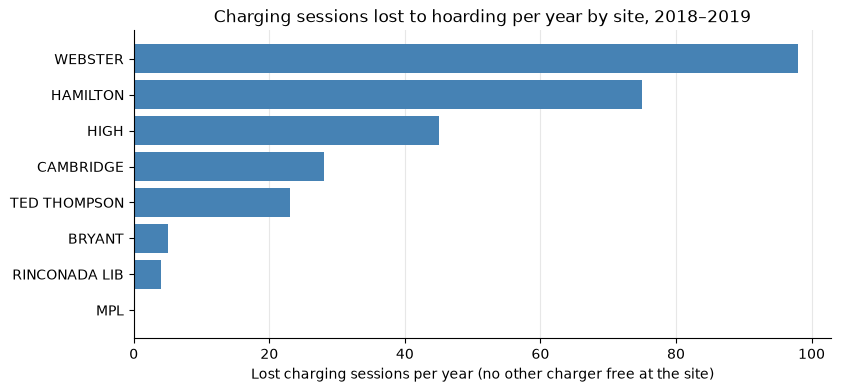

In [42]:
# site-level charging sessions lost to hoarding per year, by site (from the cell above)
site_plot = site_loss.sort_values()

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(site_plot.index, site_plot.values, color="steelblue")
ax.set_title("Charging sessions lost to hoarding per year by site, 2018–2019")
ax.set_xlabel("Lost charging sessions per year (no other charger free at the site)")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Lost revenue and the idle charge.** A blocked charger only loses revenue if another driver would have used it, and only the idle time after the first hour is due to hoarding, since a driver who leaves within an hour is not hoarding. The data hold no queues, so we estimate demand for each charger and hour as the share of days on which a session started there while the charger was free; hours when it was busy are left out, since nobody could plug in then. Each blocked hour, weighted by this demand, counts the charging sessions that would have started in it. This per-charger estimate ignores that a driver who finds one charger taken can use another at the same site. A site-level estimate therefore counts a blocked hour as lost only when every other charger at the site was busy too, with demand measured for the site as a whole. Together they give a range: daytime hoarding costs between about 280 and 1,200 charging sessions a year, with the site-level figure the closer estimate. At about 8.8 kWh per daytime session and 0.23 \$/kWh, that is about 560 to 2,300 \$ a year in energy. Even if every blocked daytime hour had been used at the average charging power of 4.6 kW, the loss would stay below 4,100 \$ a year. Those blocked hours come to about 3,900 a year, about half the 7,000 hours of Section 4.2, for two reasons: here only the idle time between 07:00 and 22:00 counts, including the morning hours of night-time sessions, and only the idle time after the first hour; Section 4.2 counts whole idle periods that start in daytime.

Every other charger at the site was busy in only 11.7% of the blocked daytime hours, and the site-level loss falls mostly at WEBSTER (about 100 sessions a year), HAMILTON (75) and HIGH (45). This changes the picture from Section 4.2: BRYANT #6 is among the chargers that lose the most daytime hours, but with six chargers at the site another one is almost always free, so BRYANT loses only about 5 sessions a year at site level.

All these figures are small next to the energy revenue of about 91,700 \$ a year, and smaller than the idle charge already collected (about 9,400 \$ a year in 2018 and 2019). The part charged in daytime sessions alone, about 7,900 \$ a year or 84% of the total, already exceeds even the upper bound. So the company already earns more from idle charges than it loses in energy. The cost of hoarding is access rather than money: about 280 charging sessions a year in which a driver would have found no charger free at the site, mostly at the busiest sites (up to 1,200 if drivers could not switch chargers). A targeted measure should therefore aim to free chargers, not to raise revenue. A reminder sent when charging ends could free more than this, since it targets all idle time of hoarding sessions, not only the time after the first hour: counted from the end of charging, the site-level loss rises from about 280 to about 580 sessions a year.

The estimate has four limits. The data contain no queues, so demand is inferred from arrivals, hour by hour: a charger counts as busy for an hour only if it is occupied for the whole of it. The per-charger figure overstates the loss, since drivers can move to a free charger at the same site, while the site-level figure may understate it a little, since a charger busy for part of an hour counts as free. The lost energy also assumes that the driver does not charge at another of the company's chargers instead; if they do, the revenue is only delayed. And the average charging power hides differences between cars and stations.

In [43]:

# STEP 4.5B — Hypothetical idle fee scenarios
# 2018–2019, with the first idle hour free.

recent = ev[
    ev["start"].dt.year.isin([2018, 2019])
].copy()

# Only idle time beyond the first hour is chargeable.
recent["chargeable_idle_hours"] = (
    recent["idle_hours"] - 1
).clip(lower=0)

total_chargeable = recent["chargeable_idle_hours"].sum()

# daytime only (idle time starting 07:00-22:00), when a blocked charger can stop another driver (Section 4.2)
day_chargeable = recent.loc[recent["period"] == "Day", "chargeable_idle_hours"].sum()

# Illustrative fees in USD per excess idle hour.
fee_rates = [1, 2, 3]

# Scenarios for behavioural reduction in chargeable idle hours.
reduction_rates = [0.00, 0.25, 0.50]

fee_rows = []

for fee_rate in fee_rates:
    for reduction in reduction_rates:

        remaining_hours = total_chargeable * (1 - reduction)
        avoided_hours = total_chargeable * reduction

        # Assumes all remaining chargeable hours are billed
        # and successfully collected.
        potential_revenue = remaining_hours * fee_rate

        fee_rows.append({
            "Fee ($/hour)": fee_rate,
            "Idle reduction (%)": reduction * 100,
            "Avoided idle hours (2018–2019)": avoided_hours,
            "Remaining chargeable hours (2018–2019)": remaining_hours,
            "Potential fee revenue, 2018–2019 ($)": potential_revenue,
            "Potential fee revenue, daytime only, 2018–2019 ($)": day_chargeable * (1 - reduction) * fee_rate
        })

fee_scenarios = pd.DataFrame(fee_rows)

print("Total chargeable idle hours (2018–2019):", round(total_chargeable, 2))
print("Daytime chargeable idle hours (2018–2019):", round(day_chargeable, 2))
display(fee_scenarios.round(2))

# 25% scenario, per year (the data cover two years): chargeable hours freed, in total and in daytime
# (daytime = idle time starting 07:00-22:00, as in Section 4.2)
print(f"25% scenario, per year: {total_chargeable * 0.25 / 2:,.0f} chargeable hours freed, "
      f"{day_chargeable * 0.25 / 2:,.0f} of them in daytime ({day_chargeable / total_chargeable * 100:.0f}%)")

Total chargeable idle hours (2018–2019): 10579.15
Daytime chargeable idle hours (2018–2019): 7187.21


,Fee ($/hour),Idle reduction (%),Avoided idle hours (2018–2019),Remaining chargeable hours (2018–2019),"Potential fee revenue, 2018–2019 ($)","Potential fee revenue, daytime only, 2018–2019 ($)"
0,1,0.0,0.00,10579.15,10579.15,7187.21
1,1,25.0,2644.79,7934.36,7934.36,5390.41
2,1,50.0,5289.57,5289.57,5289.57,3593.61
3,2,0.0,0.00,10579.15,21158.29,14374.42
4,2,25.0,2644.79,7934.36,15868.72,10780.82
5,2,50.0,5289.57,5289.57,10579.15,7187.21
6,3,0.0,0.00,10579.15,31737.44,21561.64
7,3,25.0,2644.79,7934.36,23803.08,16171.23
8,3,50.0,5289.57,5289.57,15868.72,10780.82


25% scenario, per year: 1,322 chargeable hours freed, 898 of them in daytime (68%)


**Hypothetical idle fee scenarios.** For 2018–2019, 10,579 idle hours exceeded the one-hour grace period. At a hypothetical fee of 2 \$ per additional idle hour, gross fee revenue would reach approximately 21,158 \$ if driver behaviour remained unchanged. Assuming a 25% reduction in chargeable idle hours, potential revenue would decrease to approximately 15,869 \$, while 2,645 hours would be avoided. These scenarios illustrate the trade-off between fee revenue and charger availability, rather than actual financial outcomes. Part of this revenue is already collected: since August 2017 an idle charge of about 2 \$ per hour applies to most hoarding sessions (Section 4.2), so these figures are not all new revenue. Counting only daytime hours, when a blocked charger can stop another driver, leaves 7,187 of the 10,579 chargeable hours (68%), or about 14,400 \$ over the two years (about 7,200 \$ a year) at 2 \$ per hour with no change in behaviour. Daytime here means sessions whose idle time starts between 07:00 and 22:00, as in Section 4.2.

In [44]:
# ML-based targeted intervention
# Use held-out test predictions, without further tuning.

impact = test_final.copy()

impact["risk_score"] = test_prob

# Keep 2018 and 2019 The test set starts on 31 July 2018,
# covers 31 July 2018 to December 2019.
impact = impact[
    impact["start"].dt.year.isin([2018, 2019])
].copy()

# Chargeable idle time after a one-hour grace period
impact["chargeable_idle_hours"] = (
    impact["idle_hours"] - 1
).clip(lower=0)

# Flag the highest-risk 10% of sessions
n_target = int(np.ceil(len(impact) * 0.10))

impact["targeted"] = False
top_indices = impact["risk_score"].nlargest(n_target).index
impact.loc[top_indices, "targeted"] = True

total_hours = impact["chargeable_idle_hours"].sum()
target_hours = impact.loc[
    impact["targeted"], "chargeable_idle_hours"
].sum()

total_hoarding = impact["hoarding"].sum()
target_hoarding = impact.loc[
    impact["targeted"], "hoarding"
].sum()

print("ML TARGETING RESULTS, TEST SET (31 JULY 2018 TO DECEMBER 2019)")
print("Sessions:", len(impact))
print("Targeted sessions:", n_target)
print("Hoarding cases captured:", target_hoarding)
print("Total hoarding cases:", total_hoarding)
print(
    "Share of hoarding cases captured (%):",
    round(100 * target_hoarding / total_hoarding, 2)
)
print("Total chargeable idle hours:", round(total_hours, 2))
print("Chargeable idle hours in targeted sessions:",
      round(target_hours, 2))
print(
    "Share of chargeable hours in targeted sessions (%):",
    round(100 * target_hours / total_hours, 2)
)

# daytime chargeable hours only
is_day = impact["period"] == "Day"
day_hours = impact.loc[is_day, "chargeable_idle_hours"].sum()
target_day_hours = impact.loc[impact["targeted"] & is_day, "chargeable_idle_hours"].sum()
print(f"Share of daytime chargeable hours in targeted sessions (%): {target_day_hours / day_hours * 100:.2f}")

# night-time: few sessions are flagged, but their idle periods are long
is_night = ~is_day
night_hours = impact.loc[is_night, "chargeable_idle_hours"].sum()
target_night_hours = impact.loc[impact["targeted"] & is_night, "chargeable_idle_hours"].sum()
print("Flagged night-time sessions:", (impact["targeted"] & is_night).sum())
print(f"Share of night-time chargeable hours in targeted sessions (%): {target_night_hours / night_hours * 100:.2f}")

# average chargeable hours of a hoarding session, by day and by night
is_hoarding = impact["hoarding"] == 1
day_mean = impact.loc[is_hoarding & is_day, "chargeable_idle_hours"].mean()
night_mean = impact.loc[is_hoarding & is_night, "chargeable_idle_hours"].mean()
print(f"Chargeable hours per hoarding session: daytime {day_mean:.2f}, night-time {night_mean:.2f}")

# hypothetical response to targeted reminders
targeted_rows = []

for reduction in [0.00, 0.25, 0.50]:
    avoided = target_hours * reduction

    targeted_rows.append({
        "Reduction in targeted sessions (%)": reduction * 100,
        "Avoided chargeable hours (Jul 2018–Dec 2019)": avoided,
        "Avoided daytime chargeable hours (Jul 2018–Dec 2019)": target_day_hours * reduction,
        "Remaining chargeable hours (Jul 2018–Dec 2019)": total_hours - avoided,
        "Potential fee revenue at 2 $/hour, Jul 2018–Dec 2019 ($)": 2 * (total_hours - avoided)
    })

targeted_scenarios = pd.DataFrame(targeted_rows)
display(targeted_scenarios.round(2))


ML TARGETING RESULTS, TEST SET (31 JULY 2018 TO DECEMBER 2019)
Sessions: 65256
Targeted sessions: 6526
Hoarding cases captured: 1951
Total hoarding cases: 5275
Share of hoarding cases captured (%): 36.99
Total chargeable idle hours: 7607.5
Chargeable idle hours in targeted sessions: 4018.55
Share of chargeable hours in targeted sessions (%): 52.82
Share of daytime chargeable hours in targeted sessions (%): 44.41
Flagged night-time sessions: 670
Share of night-time chargeable hours in targeted sessions (%): 70.51
Chargeable hours per hoarding session: daytime 1.10, night-time 4.29


,Reduction in targeted sessions (%),Avoided chargeable hours (Jul 2018–Dec 2019),Avoided daytime chargeable hours (Jul 2018–Dec 2019),Remaining chargeable hours (Jul 2018–Dec 2019),"Potential fee revenue at 2 $/hour, Jul 2018–Dec 2019 ($)"
0,0.0,0.00,0.00,7607.50,15215.00
1,25.0,1004.64,572.47,6602.86,13205.73
2,50.0,2009.27,1144.94,5598.23,11196.45


**ML-based targeted intervention.** In the test sessions from 31 July 2018 to December 2019, the highest-risk 10% of charging sessions captured 37% of actual hoarding cases and 53% of chargeable idle hours. This suggests that the predictive model could support targeted reminders to drivers at risk of prolonged charger occupation. In daytime, when blocked chargers matter most, the top 10% hold 44% of the chargeable hours, against 53% of all chargeable hours. The gap comes from the night: only 670 of the flagged sessions are night-time sessions, but they hold 71% of the night-time chargeable hours, because night hoarding lasts much longer (4.3 against 1.1 chargeable hours per hoarding session).

Under a hypothetical 25% reduction in chargeable idle hours among targeted sessions, approximately 1,005 hours could be avoided, while gross idle-fee revenue at 2 \$ per hour would decrease from 15,215 \$ to 13,206 \$. About 570 of those hours (57%) fall in daytime, when another driver could have used the charger. These scenarios count only the idle time after the first hour; a reminder sent when charging ends could free more, since it also targets the first idle hour (see the lost-energy estimate above).

These results are scenario-based estimates, not observed intervention effects. Actual benefits would depend on driver responses, implementation costs, and whether released charging capacity could be used by other vehicles.

In [45]:
# ML targeting vs random targeting
# Compare equal-sized groups on the same held-out sessions.

rng = np.random.default_rng(42)

n = len(impact)
n_target = int(impact["targeted"].sum())
n_simulations = 1000

hoarding = impact["hoarding"].to_numpy()
idle_hours = impact["chargeable_idle_hours"].to_numpy()
ml_mask = impact["targeted"].to_numpy()

total_hoarding = hoarding.sum()
total_idle = idle_hours.sum()

# ML targeting results
ml_cases = hoarding[ml_mask].sum()
ml_hours = idle_hours[ml_mask].sum()

# Random targeting simulations
random_cases = []
random_hours = []

for _ in range(n_simulations):
    indices = rng.choice(
        n,
        size=n_target,
        replace=False
    )

    random_cases.append(hoarding[indices].sum())
    random_hours.append(idle_hours[indices].sum())

random_cases = np.array(random_cases)
random_hours = np.array(random_hours)

# hour x station, refitted on fit + validation
hour_rate_train = train_final.groupby("start_hour")["hoarding"].mean()
pair_rate_train = (train_final.groupby(["start_hour", train_final["station"].astype(str)])["hoarding"]
                   .mean().to_dict())

# the rate of its hour x station pair, or the hour rate if the pair is new
pairs = zip(impact["start_hour"], impact["station"].astype(str))
rule_score = pd.Series([pair_rate_train.get(pair, np.nan) for pair in pairs], index=impact.index)
rule_score = rule_score.fillna(impact["start_hour"].map(hour_rate_train))

# the rule picks the same number of sessions as the model
# sessions in the same hour x station pair share one score, ties keep the time order (stable sort)
rule_top = rule_score.sort_values(ascending=False, kind="stable").index[:n_target]
rule_mask = impact.index.isin(rule_top)
rule_cases = hoarding[rule_mask].sum()
rule_hours = idle_hours[rule_mask].sum()

# rule that uses the driver: the past hoarding rate, same number of sessions
past_top = impact["prev_hoarding_rate"].sort_values(ascending=False, kind="stable").index[:n_target]
past_mask = impact.index.isin(past_top)

# daytime chargeable hours (idle time starting 07:00-22:00); random picks get 10% on average by construction
is_day_arr = (impact["period"] == "Day").to_numpy()
day_total = idle_hours[is_day_arr].sum()


def captured(mask):
    return [100 * hoarding[mask].sum() / total_hoarding,
            100 * idle_hours[mask].sum() / total_idle,
            100 * idle_hours[mask & is_day_arr].sum() / day_total]


comparison = pd.DataFrame(
    [captured(ml_mask), captured(past_mask), captured(rule_mask),
     [100 * random_cases.mean() / total_hoarding, 100 * random_hours.mean() / total_idle, 100 * n_target / n]],
    columns=["Hoarding cases captured (%)", "Chargeable idle hours captured (%)",
             "Daytime chargeable idle hours captured (%)"],
    index=["ML targeting", "Rule: driver's past rate",
           "Rule: hour x station (no driver information)", "Random targeting (mean)"])

display(comparison.round(2))

print(
    "ML lift in hoarding cases:",
    round(ml_cases / random_cases.mean(), 2)
)

print(
    "ML lift in chargeable idle hours:",
    round(ml_hours / random_hours.mean(), 2)
)

print(f"ML lift over the hour x station rule: {ml_cases / rule_cases:.2f} (cases), {ml_hours / rule_hours:.2f} (hours)")
print(f"ML lift over the past-rate rule: {ml_cases / hoarding[past_mask].sum():.2f} (cases), "
      f"{ml_hours / idle_hours[past_mask].sum():.2f} (hours)")

print(
    "Random targeting 95% simulation range "
    "for captured idle hours:",
    np.round(
        np.percentile(random_hours, [2.5, 97.5]),
        2
    )
)


,Hoarding cases captured (%),Chargeable idle hours captured (%),Daytime chargeable idle hours captured (%)
ML targeting,36.99,52.82,44.41
Rule: driver's past rate,35.75,48.61,43.61
Rule: hour x station (no driver information),14.27,24.42,9.39
Random targeting (mean),9.99,10.00,10.00


ML lift in hoarding cases: 3.7
ML lift in chargeable idle hours: 5.28
ML lift over the hour x station rule: 2.59 (cases), 2.16 (hours)
ML lift over the past-rate rule: 1.03 (cases), 1.09 (hours)
Random targeting 95% simulation range for captured idle hours: [659.42 870.11]


**ML targeting versus a simple rule and random targeting.** We compared the highest-risk 10% of charging sessions identified by the gradient boosting model with 1,000 random selections of the same size. ML targeting captured 37% of actual hoarding cases and 53% of chargeable idle hours, compared with approximately 10% for random targeting. This corresponds to a 3.7-fold improvement in hoarding-case capture and a 5.3-fold improvement in chargeable idle-hour capture. A simple rule that picks the drivers with the highest past hoarding rate does almost as well: 36% of hoarding cases, 49% of chargeable hours and 44% of daytime chargeable hours, against 37%, 53% and 44% for the model. The hour × station rule, which has no information about the driver, captures 14% of cases and, in daytime, only 9% of chargeable hours, no better than random picks.

These findings suggest that prioritizing drivers by their hoarding history could improve the efficiency of targeted reminders. However, the analysis demonstrates predictive targeting performance, not a causal reduction in idle time or realized financial benefits.

-----------------------------------------

## 4.6. Conclusions <a class="anchor" id="p4_6"></a>
  
[Back to TOC](#toc)

**How much is lost.** In 2018 and 2019, with nearly all sessions paid, hoarding still blocked about 3,900 daytime charger hours a year after the first idle hour (idle time between 07:00 and 22:00). Weighted by how often a free charger is actually wanted, these blocked hours would have turned away between about 280 and 1,200 charging sessions a year (about 560 to 2,300 \$ in energy), with the site-level figure the closer estimate, since a driver can usually move to another charger at the same site. That is small next to the energy revenue (about 91,700 \$ a year) and below the idle charge that the fee data show is already collected (about 9,400 \$ a year). The cost of hoarding is access to chargers more than revenue. A reminder sent when charging ends could free more than this, since it targets all idle time of hoarding sessions, not only the time after the first hour: counted from the end of charging, the site-level loss rises from about 280 to about 580 sessions a year.

**Can it be predicted at plug-in.** Yes, mostly from the driver's own history. A gradient boosting model on the plug-in hour, the station and the driver's history reaches a test PR-AUC of 0.278 (95% interval 0.24 to 0.32) against a base rate of 7.9%. Most of this comes from the driver: their past hoarding rate alone reaches 0.226. The model ranks sessions better overall (+0.05 PR-AUC, both for drivers with and without history), but among the 10% riskiest sessions it is almost level with the simple rule (37% against 36% of hoarding sessions, and 44% of daytime chargeable hours for both). For new drivers both are weak. The result holds for the stricter >2 h target. Leaving out the free-period data does not change it, although training on more recent data seems to help a little (PR-AUC +0.016), which suggests that retraining the model regularly may matter more than choosing which period to train on.

**What to do.** An idle charge of about 2 \$ per hour already exists, yet daytime hoarding persists. It is never charged at HAMILTON #1, which sits at one of the three sites that lose the most sessions, so extending the charge there is a simple step; the other chargers without it (MPL #1 to #3 and RINCONADA LIB 1 to 3) lose almost no sessions. A fee that depends on a prediction would be hard to justify, since two drivers idling for the same time would pay differently, and about 70% of the sessions flagged by either the model or the simple rule do not hoard. A reminder when charging ends fits better, sent to drivers with a history of hoarding at the sites where hoarding most often leaves no charger free (WEBSTER, HAMILTON and HIGH). Sending it to everyone would cost no more, but drivers who rarely hoard would soon learn to ignore it, and a simple rule on past hoarding picks the right drivers almost as well as the model. The model pays off when the provider wants a full risk ranking or a list longer than the top 10%. Freeing chargers also lowers idle-charge revenue: if the targeted drivers in the test period (31 July 2018 to December 2019) cut their chargeable idle time by 25%, about 1,000 hours would be freed, about 570 of them in daytime, while fee revenue at 2 \$ per hour would fall from about 15,200 \$ to 13,200 \$ over those 17 months. The provider would trade some fee income for access, which is where hoarding actually costs it. The data cannot show whether reminders shorten idle time; a trial at a few stations would answer that. So, to the research question: drivers likely to hoard can be identified at plug-in, mostly from their own history, and this flag suits a targeted reminder rather than a targeted fee.

**Limits.** Demand for a blocked charger is inferred from arrivals, since the data hold no queues, and a driver who charges elsewhere in the network only delays the revenue. The idle charge is read from the fees, not from a published tariff. Driver history weighs old and recent sessions equally, including those from the free period, so giving recent sessions more weight might help. All figures are associations, not causal effects. With queue or waitlist data, lost demand could be counted directly instead of estimated.